In [1]:
pacman::p_load(dplyr,ggplot2,lubridate,ggridges,ggmap,patchwork,ggnewscale,
               RColorBrewer,trend,ggpmisc)

In [2]:
species_codes = read.csv(file.path("../data","CC_plankton_200_2021_metadata_species.csv")) %>%
    dplyr::mutate(SPEC_CODE_MUT=dplyr::case_when(!is.na(as.numeric(as.character(SPEC_CODE))) ~ 
                                                 as.character(as.numeric(as.character(SPEC_CODE))),
                                                 TRUE ~ as.character(SPEC_CODE)))

plankton_metadata = read.csv("../data/CC_plankton_200_2021_metadata_species.csv")
plankton_counts = read.csv("../data/cc_plankton_2020_202307.csv")
merged_pkton = plankton_counts %>% dplyr::left_join(plankton_metadata)

paired_data = read.csv(file.path("../data","cc_plankton_2000_2021.csv")) %>%
    dplyr::mutate(SPEC_CODE = as.character(SPEC_CODE)) %>%
    dplyr::mutate(SPEC_CODE_MUT=dplyr::case_when(!is.na(as.numeric(as.character(SPEC_CODE))) ~ 
                                                 as.character(as.numeric(as.character(SPEC_CODE))),
                                                 TRUE ~ as.character(SPEC_CODE)))%>%
    dplyr::left_join(species_codes,by=c("SPEC_CODE_MUT")) %>%
    dplyr::bind_rows(merged_pkton) %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV,format='%d-%b-%Y %H:%M:%S')) %>%
    dplyr::filter(!(trimws(GROUP_ID) %in% c("COPEPOD",
                                             "OTHER (ZOO)",
                                             "BARNACLE"))) 

Warning message:
“There were 2 warnings in `dplyr::mutate()`.
The first warning was:
ℹ In argument: `SPEC_CODE_MUT = dplyr::case_when(...)`.
Caused by warning:
! NAs introduced by coercion
ℹ Run `dplyr::last_dplyr_warnings()` to see the 1 remaining warning.”
Joining with `by = join_by(SPEC_CODE)`
Warning message:
“There were 2 warnings in `dplyr::mutate()`.
The first warning was:
ℹ In argument: `SPEC_CODE_MUT = dplyr::case_when(...)`.
Caused by warning:
! NAs introduced by coercion
ℹ Run `dplyr::last_dplyr_warnings()` to see the 1 remaining warning.”


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  and UNIT_CODE.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, and DESCR.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, and
  DESCR.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, and GROUP_ID.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by regime, DESCR, and GROUP_ID.
ℹ Output is grouped by regime and DESCR.
ℹ Use `summarise(.groups = "drop_last")` to silence this

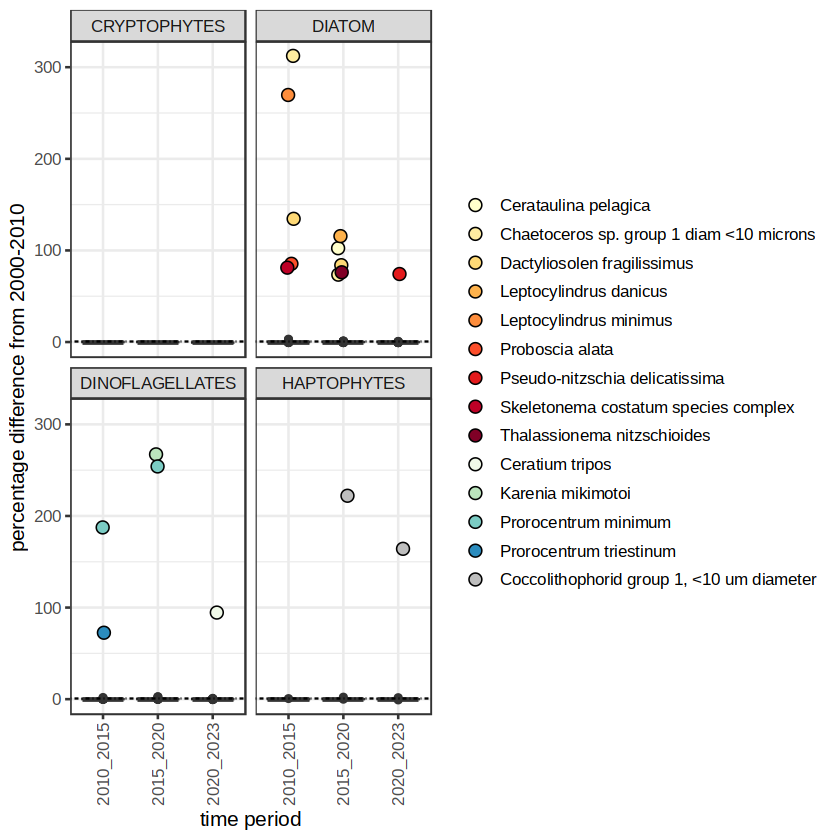

In [100]:
infill_dates = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES",
                                        "CRYPTOPHYTES")) %>%
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date"),names_from="DESCR",values_from="Group_Ct")

infill_dates[is.na(infill_dates)]=0

group_connect = paired_data %>% dplyr::select(GROUP_ID,DESCR) %>%
    dplyr::mutate(DESCR=trimws(DESCR)) %>%
    dplyr::distinct() %>% dplyr::filter(!is.na(GROUP_ID) & !is.na(DESCR))

for_plotting = infill_dates %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::mutate(GROUP_ID = case_when(grepl("DIATOM",GROUP_ID)~"DIATOM",
                                      TRUE~GROUP_ID)) %>%
    dplyr::mutate(Year = year(as.Date(Date,format='%d-%b-%Y %H:%M:%S')),
                 Month = month(as.Date(Date,format='%d-%b-%Y %H:%M:%S'))) %>%
    dplyr::mutate(regime = case_when(Year > 2020 ~ "2020_2023",
                                     Year > 2015 ~ "2015_2020",
                                     Year > 2010 ~ "2010_2015",
                                    TRUE ~"early")) %>%
    dplyr::group_by(regime,DESCR,GROUP_ID) %>% dplyr::summarize(meanCt = mean(Group_Ct)) %>%
    tidyr::pivot_wider(id_cols=c("DESCR","GROUP_ID"),names_from="regime",
                       values_from="meanCt")%>%
    tidyr::pivot_longer(cols=!(starts_with("GROUP_ID")|starts_with("DESCR")|starts_with("early")),
                       names_to="regime",
                       values_to="value") %>%
    dplyr::mutate(labeled_pts = case_when(((value)-(early))/(early+0.01)> 0.7~DESCR,
                                          TRUE~NA))

seasonal_shifts = ggplot(for_plotting)+
    geom_boxplot(aes(x=regime,y=((value)-(early))/(early+0.01),group=paste0(GROUP_ID,regime)))+new_scale_fill() + 
    geom_jitter(data=for_plotting %>% dplyr::filter(!is.na(labeled_pts)) %>%
               dplyr::arrange(GROUP_ID) %>% 
               dplyr::mutate(labeled_pts=factor(labeled_pts,levels=(for_plotting %>% 
                                                dplyr::distinct(labeled_pts,.keep_all=TRUE) %>%
                                                dplyr::filter(!is.na(labeled_pts)) %>%
               dplyr::arrange(GROUP_ID))$labeled_pts)),
               aes(x=regime,y=((value)-(early))/(early+0.01)*100,group=paste0(regime,GROUP_ID),
                   fill=labeled_pts), na.rm=TRUE,pch=21,size=3,width=0.1,height=0)+ 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + facet_wrap(~GROUP_ID,nrow=3) + 
    geom_hline(aes(yintercept=0.75),linetype="dotdash") + theme_bw(base_size=12) + 
    ylab("percentage difference from 2000-2010")+ 
    scale_fill_manual(values=c(brewer.pal(9, "YlOrRd"),
                               brewer.pal(4,"GnBu"),"gray"),name="") + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + xlab("time period")

seasonal_shifts

In [101]:
for_prob_test = infill_dates %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR"))%>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|
                                 grepl("Emiliania",DESCR)|
                                 grepl("Isochrysis",DESCR)~"Isochrysidales",
                                 grepl("Prorocentru",DESCR)~"Prorocentrales",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales",
                                 grepl("nitzschia",tolower(DESCR))|
                                 grepl("Bacillaria",DESCR)|
                                 grepl("Cylindrotheca",DESCR)|
                                 grepl("Fragilariopsis",DESCR)|
                                 grepl("Denticula",DESCR)~"Bacillariales",
                                 grepl("Guinardia",DESCR)|grepl("Proboscia",DESCR)|
                                 grepl("Dactyliosolen",DESCR)|grepl("Rhizosolenia",DESCR)~
                                 "Rhizosoleniales",
                                 grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)~
                                 "Prymesiophyte",
                                 grepl("Hemiaulus",DESCR)|grepl("Eucampia",DESCR)|
                                 grepl("Cerataulina",DESCR)~
                                 "Hemiaulales",
                                 grepl("Coscino",DESCR)~
                                 "Coscinodiscus",
                                 grepl("Gymnodinium",DESCR)|grepl("Gyrodinium",DESCR)|
                                 grepl("Karenia",DESCR)|grepl("Amphidinium",DESCR)|
                                 grepl("Akashiwo",DESCR)~
                                 "Gymnodiniales",
                                 grepl("Guinardia",DESCR)|grepl("Proboscia",DESCR)|
                                 grepl("Dactyliosolen",DESCR)|grepl("Rhizosolenia",DESCR)~
                                 "Rhizosoleniales",
                                 grepl("Thecate",DESCR)~
                                 "Suessiales",
                                 grepl("Gonyaulax",DESCR)|grepl("ceratium",tolower(DESCR))|
                                 grepl("Tripos",DESCR)~
                                 "Gonyaulacales",
                                 grepl("Chaetocero",DESCR)~"Chaetocerotales",
                                 grepl("Phaeo",DESCR)~
                                 "Phaeocystales")) %>%
    dplyr::group_by(type,Date) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

all_stats = data.frame()
for (curr_group in unique(for_prob_test$type)) {
    frame_for_test = for_prob_test %>% dplyr::filter(type==curr_group) %>%
        dplyr::arrange(Date)
    stats_test = mk.test(frame_for_test$Group_Ct,alternative = "greater")
    curr_fr = data.frame(statistic = stats_test$statistic,
               organism = curr_group,
               p_value = stats_test$p.value,
               total_abundance = sum(frame_for_test$Group_Ct),
               avg_abundance = mean(frame_for_test$Group_Ct))
    all_stats = all_stats %>% dplyr::bind_rows(curr_fr)
    print(curr_group)
    print(mk.test(frame_for_test$Group_Ct,alternative="greater"))
               
}

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type and Date.
ℹ Output is grouped by type.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(type, Date))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


[1] "Bacillariales"

	Mann-Kendall trend test

data:  frame_for_test$Group_Ct
z = 1.67, n = 190, p-value = 0.04746
alternative hypothesis: true S is greater than 0
sample estimates:
           S         varS          tau 
1.463000e+03 7.664497e+05 8.211505e-02 

[1] "Chaetocerotales"

	Mann-Kendall trend test

data:  frame_for_test$Group_Ct
z = -0.13654, n = 190, p-value = 0.5543
alternative hypothesis: true S is greater than 0
sample estimates:
            S          varS           tau 
-1.200000e+02  7.595607e+05 -6.849623e-03 

[1] "Coscinodiscus"

	Mann-Kendall trend test

data:  frame_for_test$Group_Ct
z = -1.6068, n = 190, p-value = 0.946
alternative hypothesis: true S is greater than 0
sample estimates:
            S          varS           tau 
-9.410000e+02  3.422383e+05 -9.169864e-02 

[1] "Cryptomonadales"

	Mann-Kendall trend test

data:  frame_for_test$Group_Ct
z = -3.0283, n = 190, p-value = 0.9988
alternative hypothesis: true S is greater than 0
sample estimates:
       

ERROR: Error in mk.test(frame_for_test$Group_Ct, alternative = "greater"): 'x' must have at least 3 elements


In [314]:
infill_dates = read.csv("../output/metaT_informed_all_sol_haldane_denom_new_graz_inhib_half_sat_2_alpha_1.csv")%>%
    dplyr::mutate(abund=case_when(abund<0~0,
                                  TRUE~abund)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(DateTime,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::filter(DateTimeForm>as.Date("2000-03-01",format="%Y-%m-%d"))%>%
    dplyr::group_by(DateTimeForm,taxon)%>%dplyr::summarize(abund=mean(abund))%>%
    dplyr::ungroup() %>%
    dplyr::group_by(taxon) %>%
    dplyr::mutate(z_score=(abund-mean(abund))/sd(abund)) %>%
    dplyr::mutate(taxon=case_when(taxon=="Chaetocerotophycidae"~"Chaetocerotales",
                                  taxon=="Leptocylindrales"~"Leptocylindrus",
                                  taxon=="Coscinodiscales"~"Coscinodiscus",
                                  TRUE~taxon))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by DateTimeForm and taxon.
ℹ Output is grouped by DateTimeForm.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(DateTimeForm, taxon))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


In [315]:
infill_dates_allometry = read.csv("../output/../output/allometry_all_sol_haldane_denom_new_graz_inhib_half_sat_2_alpha_1.csv")%>%
    dplyr::mutate(abund=case_when(abund<0~0,
                                  TRUE~abund)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(DateTime,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::filter(DateTimeForm>as.Date("2000-03-01",format="%Y-%m-%d"))%>%
    dplyr::group_by(DateTimeForm,taxon)%>%dplyr::summarize(abund=mean(abund))%>%
    dplyr::ungroup() %>%
    dplyr::group_by(taxon) %>%
    dplyr::mutate(z_score=(abund-mean(abund))/sd(abund)) %>%
    dplyr::mutate(taxon=case_when(taxon=="Chaetocerotophycidae"~"Chaetocerotales",
                                  taxon=="Leptocylindrales"~"Leptocylindrus",
                                  taxon=="Coscinodiscales"~"Coscinodiscus",
                                  TRUE~taxon))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by DateTimeForm and taxon.
ℹ Output is grouped by DateTimeForm.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(DateTimeForm, taxon))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


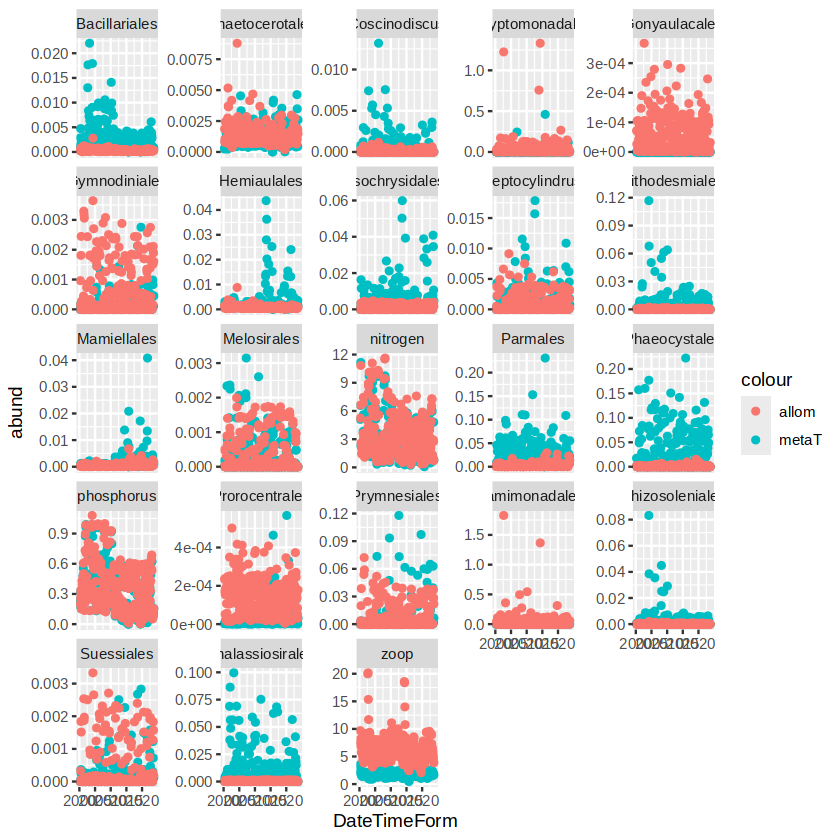

In [316]:
ggplot(infill_dates %>% dplyr::left_join(infill_dates_allometry %>% 
                                  dplyr::rename(c("allometry"="abund")),
                                 by=c("DateTimeForm","taxon")) %>%
    dplyr::mutate(percent_difference = (allometry-abund)/abund*100)) + 
    geom_point(aes(x=DateTimeForm,y=abund,color="metaT")) + 
    geom_point(aes(x=DateTimeForm,y=allometry,color="allom"))+
    facet_wrap(~taxon,scales="free_y")

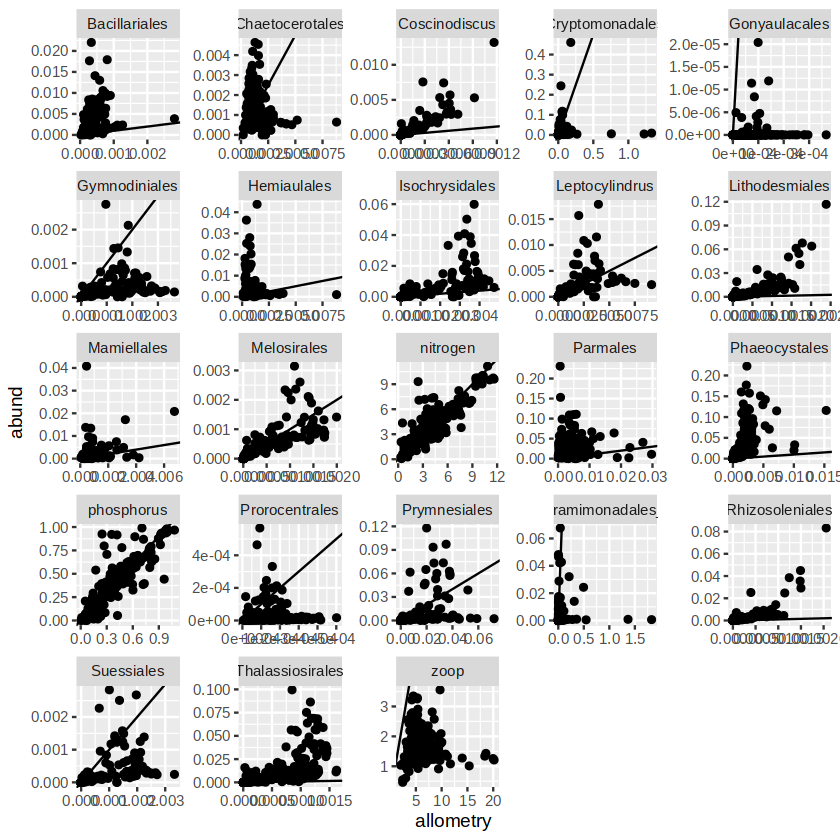

In [317]:
ggplot(infill_dates %>% dplyr::left_join(infill_dates_allometry %>% 
                                  dplyr::rename(c("allometry"="abund")),
                                 by=c("DateTimeForm","taxon")) %>%
    dplyr::mutate(percent_difference = (allometry-abund)/abund*100)) + 
    geom_point(aes(x=allometry,y=abund)) +
    geom_abline(aes(intercept=0,slope=1))+
    facet_wrap(~taxon,scales="free")

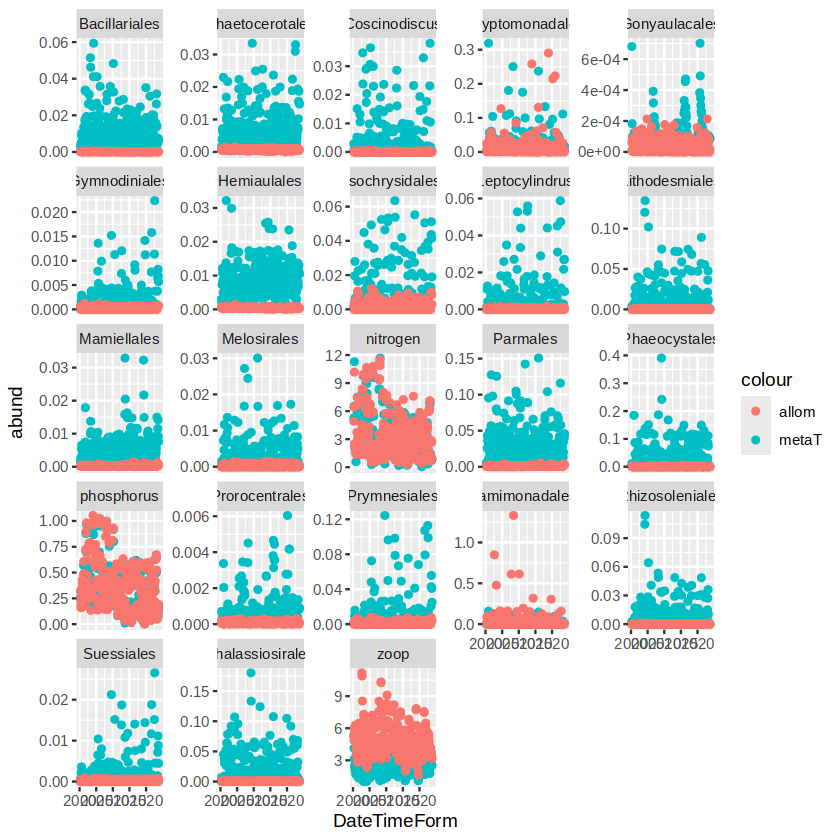

In [90]:
ggplot(infill_dates %>% dplyr::left_join(infill_dates_allometry %>% 
                                  dplyr::rename(c("allometry"="abund")),
                                 by=c("DateTimeForm","taxon")) %>%
    dplyr::mutate(percent_difference = (allometry-abund)/abund*100)) + 
    geom_point(aes(x=DateTimeForm,y=abund,color="metaT")) + 
    geom_point(aes(x=DateTimeForm,y=allometry,color="allom"))+
    facet_wrap(~taxon,scales="free_y")

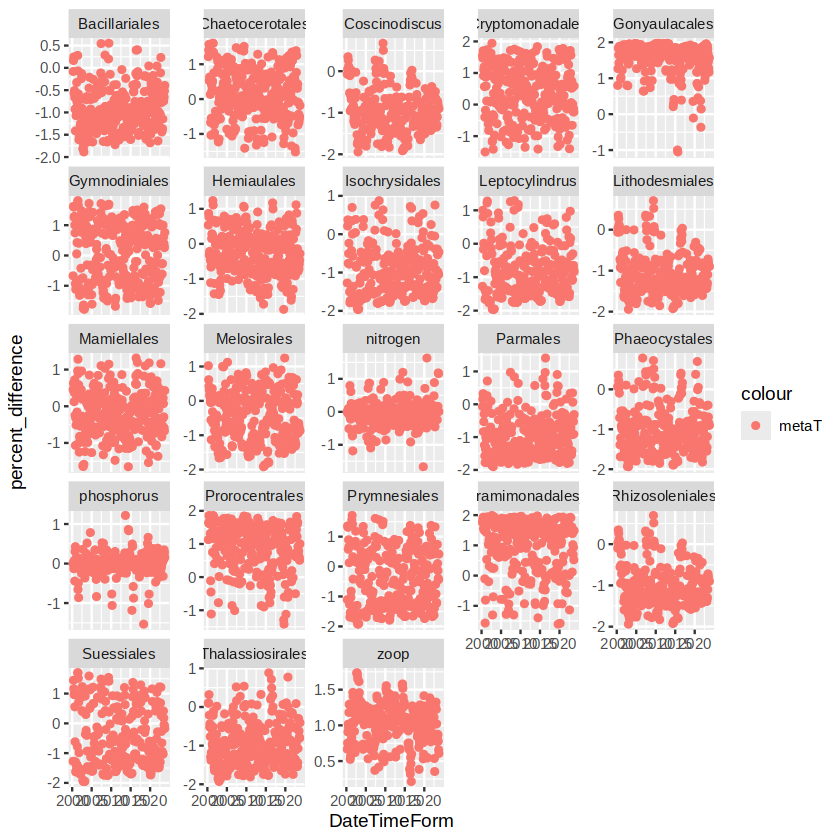

In [105]:
ggplot(infill_dates %>% dplyr::left_join(infill_dates_allometry %>% 
                                  dplyr::rename(c("allometry"="abund")),
                                 by=c("DateTimeForm","taxon")) %>%
    dplyr::mutate(percent_difference = (allometry-abund)/((allometry+abund)/2))) + 
    geom_point(aes(x=DateTimeForm,y=percent_difference,color="metaT")) +
    facet_wrap(~taxon,scales="free_y")

Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 3978 rows containing missing values or values outside the scale range
(`geom_point()`).”


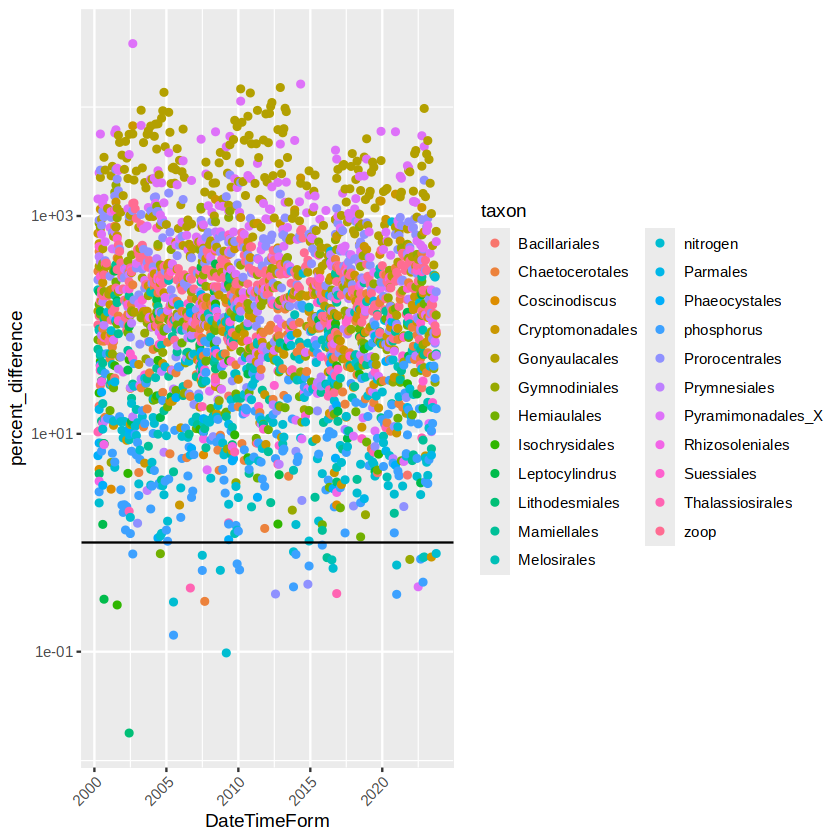

In [106]:
ggplot(infill_dates %>% dplyr::left_join(infill_dates_allometry %>% 
                                  dplyr::rename(c("allometry"="abund")),
                                 by=c("DateTimeForm","taxon")) %>%
    dplyr::mutate(percent_difference = (allometry-abund)/abund*100)) + 
    geom_point(aes(x=DateTimeForm,y=percent_difference,color=taxon))+
    scale_y_log10() + 
    geom_hline(aes(yintercept=10^0))+
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

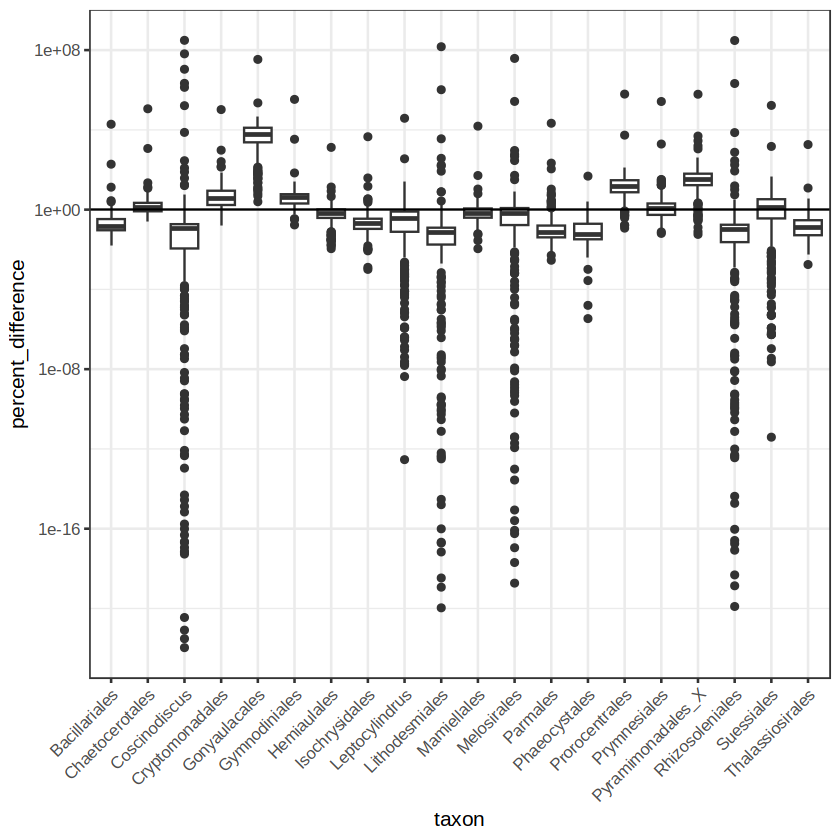

In [318]:
ggplot(infill_dates %>% dplyr::left_join(infill_dates_allometry %>% 
                                  dplyr::rename(c("allometry"="abund")),
                                 by=c("DateTimeForm","taxon")) %>%
    dplyr::mutate(percent_difference = allometry/abund) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=taxon,y=percent_difference))+
    geom_hline(aes(yintercept=1))+
    scale_y_log10() + 
    theme_bw(base_size=12)+ 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 304 rows containing non-finite outside the scale range
(`stat_boxplot()`).”


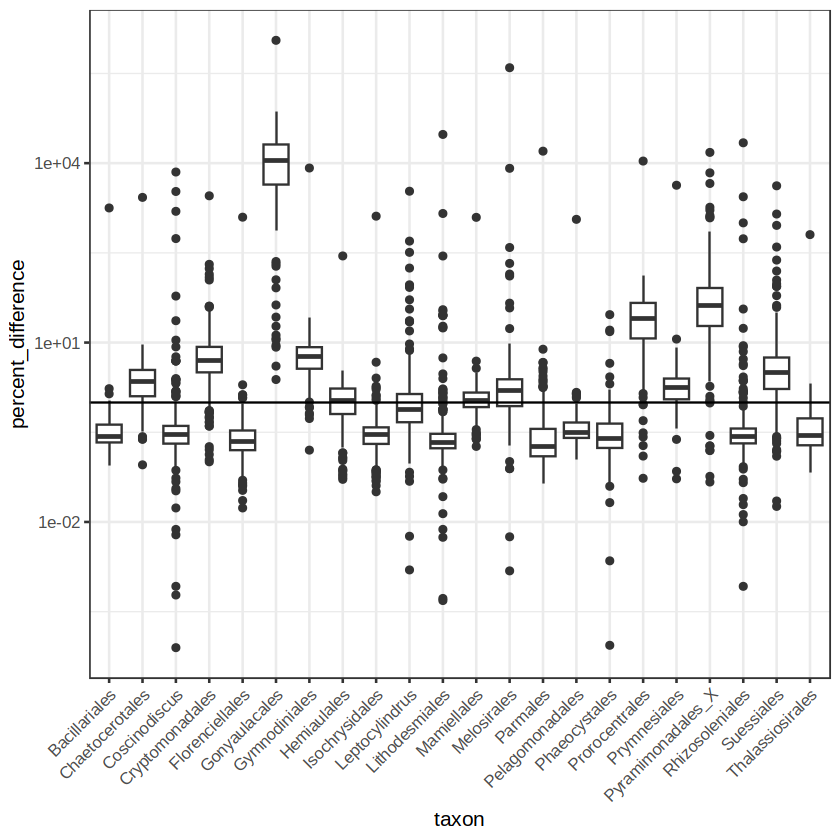

In [201]:
ggplot(infill_dates %>% dplyr::left_join(infill_dates_allometry %>% 
                                  dplyr::rename(c("allometry"="abund")),
                                 by=c("DateTimeForm","taxon")) %>%
    dplyr::mutate(percent_difference = allometry/abund) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=taxon,y=percent_difference))+
    geom_hline(aes(yintercept=1))+
    scale_y_log10() + 
    theme_bw(base_size=12)+ 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 310 rows containing non-finite outside the scale range
(`stat_boxplot()`).”


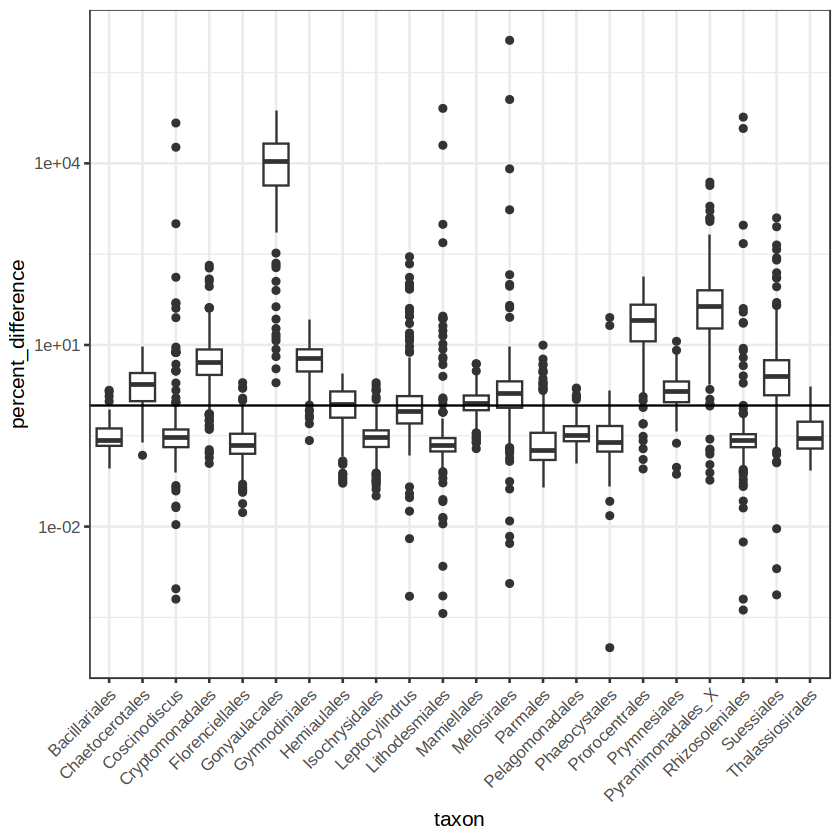

In [205]:
ggplot(infill_dates %>% dplyr::left_join(infill_dates_allometry %>% 
                                  dplyr::rename(c("allometry"="abund")),
                                 by=c("DateTimeForm","taxon")) %>%
    dplyr::mutate(percent_difference = allometry/abund) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=taxon,y=percent_difference))+
    geom_hline(aes(yintercept=1))+
    scale_y_log10() + 
    theme_bw(base_size=12)+ 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_line()`).”


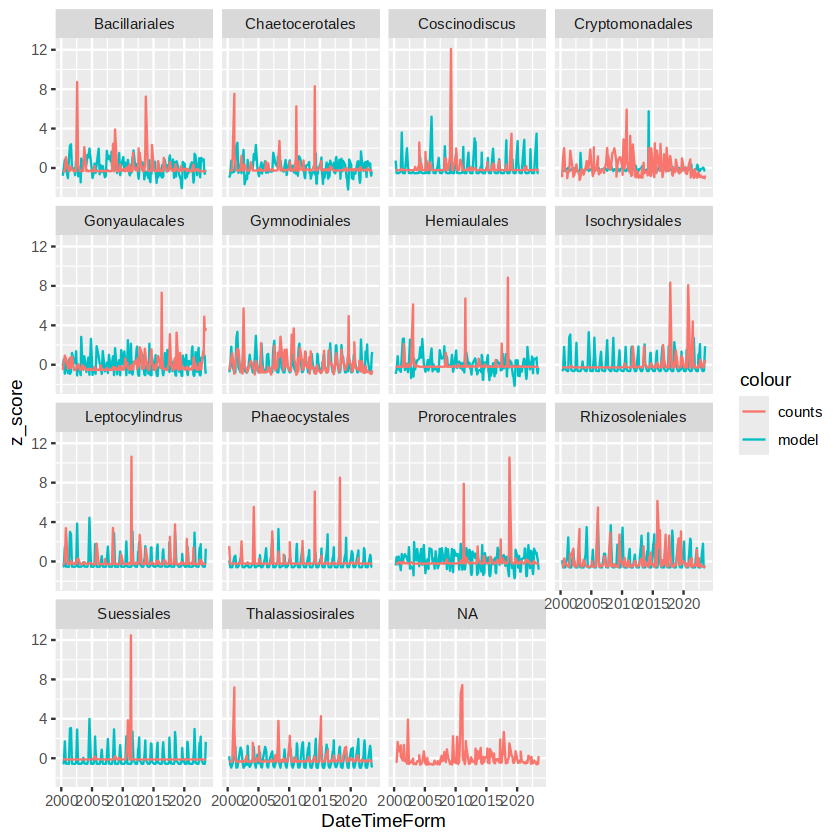

In [306]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_line(aes(x=DateTimeForm,y=z_score,color="model"))+
    geom_line(aes(x=DateTimeForm,y=z_score_obs,color="counts"))+
    facet_wrap(~type)

In [109]:
unique(for_prob_test$type)

[1] "Bacillariales"    "Chaetocerotales"  "Coscinodiscus"    "Cryptomonadales" 
 [5] "Gonyaulacales"    "Gymnodiniales"    "Hemiaulales"      "Isochrysidales"  
 [9] "Leptocylindrus"   "Phaeocystales"    "Prorocentrales"   "Rhizosoleniales" 
[13] "Suessiales"       "Thalassiosirales" NA

Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_line()`).”


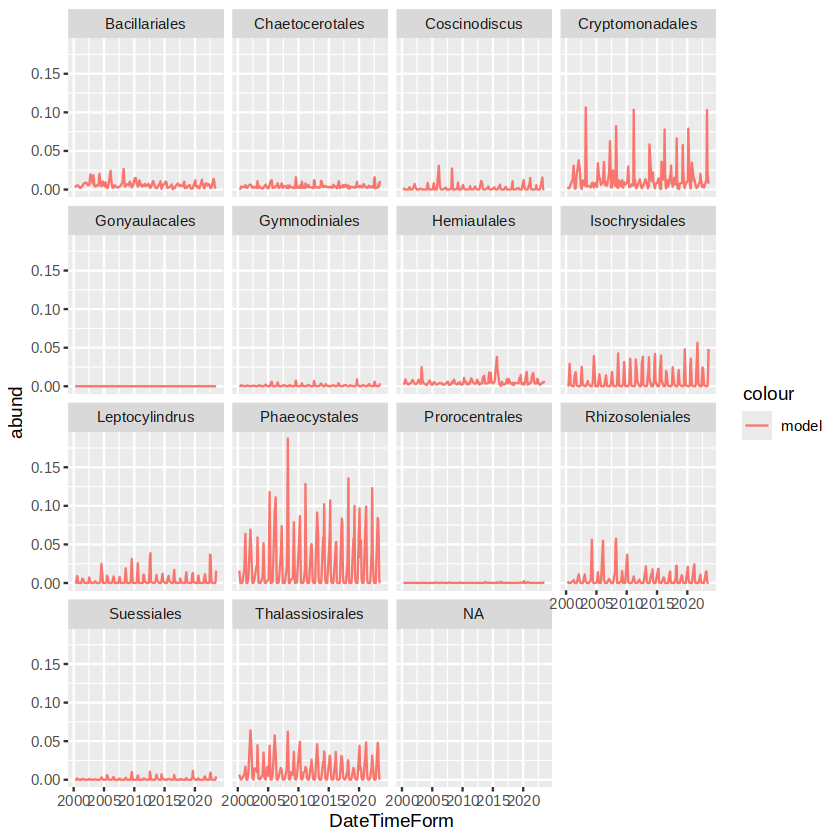

In [288]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_line(aes(x=DateTimeForm,y=abund,color="model"))+
    facet_wrap(~type)

Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_line()`).”


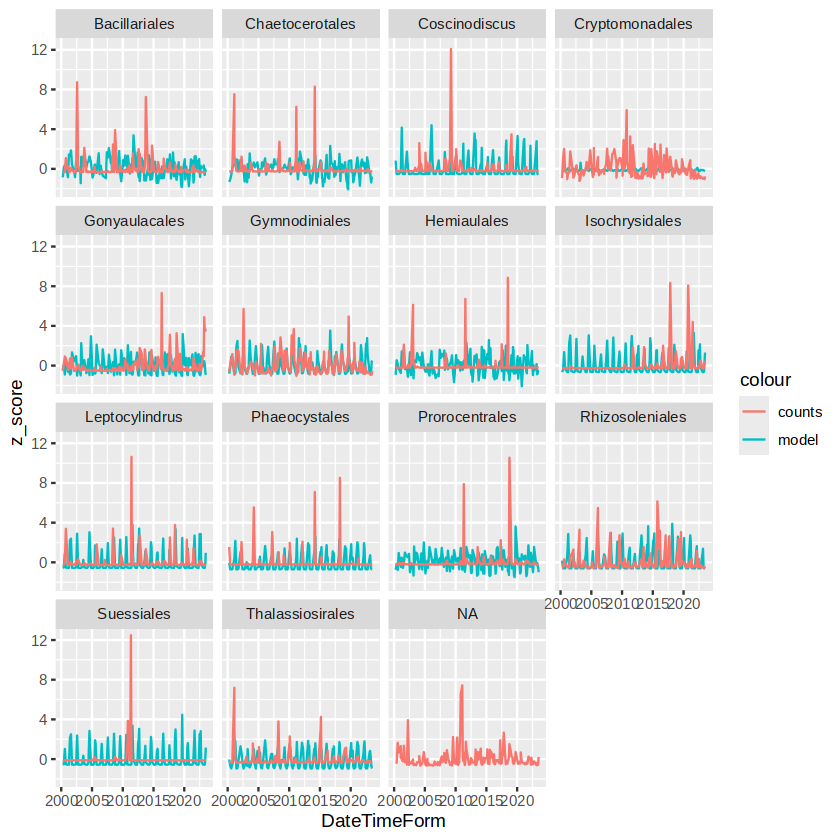

In [156]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_line(aes(x=DateTimeForm,y=z_score,color="model"))+
    geom_line(aes(x=DateTimeForm,y=z_score_obs,color="counts"))+
    facet_wrap(~type)

In [289]:
types_for_sum = intersect(for_prob_test$type,infill_dates_allometry$taxon)

In [290]:
summarized_for_test = for_prob_test %>% dplyr::filter(type%in%types_for_sum) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::group_by(DateTimeForm) %>% dplyr::summarize(summedgrpct=sum(Group_Ct)) %>%
    dplyr::mutate(dataset="counts") %>%
    dplyr::bind_rows(infill_dates %>% dplyr::group_by(DateTimeForm) %>%
       dplyr::summarize(summedgrpct=sum(abund)) %>% dplyr::mutate(dataset="metaT"))%>%
    dplyr::bind_rows(infill_dates_allometry %>% dplyr::group_by(DateTimeForm) %>%
       dplyr::summarize(summedgrpct=sum(abund)) %>% dplyr::mutate(dataset="allometry")) %>%
    dplyr::group_by(dataset) %>%
    dplyr::mutate(zscore = (summedgrpct-mean(summedgrpct))/sd(summedgrpct))

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 114 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 114 rows containing missing values or values outside the scale range
(`geom_point()`).”


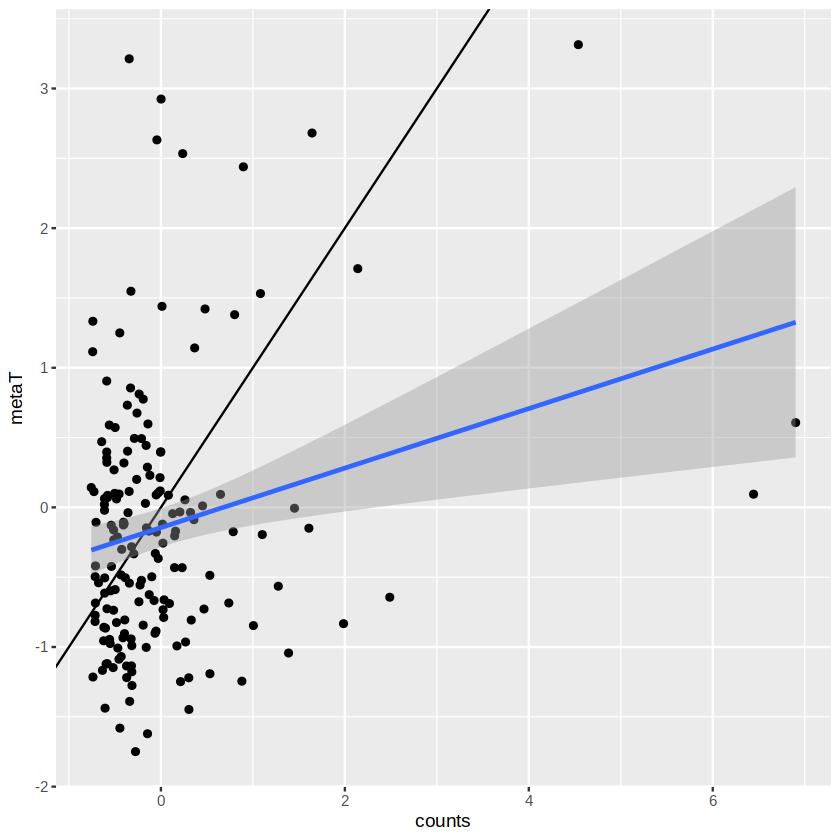

In [291]:
ggplot(summarized_for_test %>% tidyr::pivot_wider(id_cols = c("DateTimeForm"),
                                            names_from=dataset,
                                            values_from=zscore)) + 
    geom_point(aes(x=counts,y=metaT))  +
    geom_abline(aes(intercept=0,slope=1))+
    geom_smooth(aes(x=counts,y=metaT),method="lm")

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 114 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 114 rows containing missing values or values outside the scale range
(`geom_point()`).”


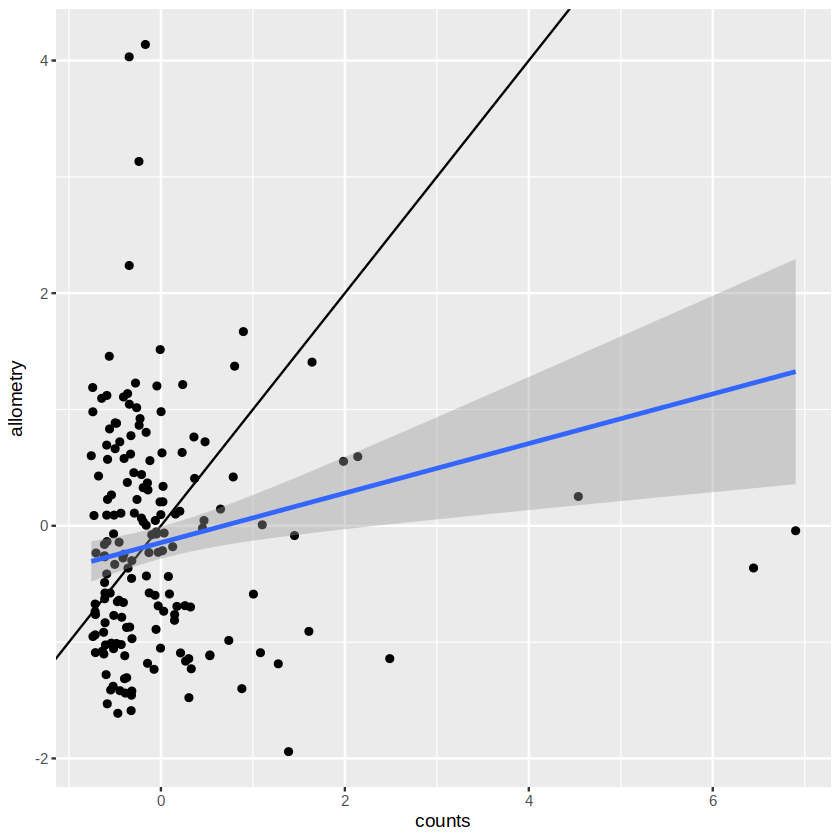

In [292]:
ggplot(summarized_for_test %>% tidyr::pivot_wider(id_cols = c("DateTimeForm"),
                                            names_from=dataset,
                                            values_from=zscore)) + 
    geom_point(aes(x=counts,y=allometry))  +
    geom_abline(aes(intercept=0,slope=1))+
    geom_smooth(aes(x=counts,y=metaT),method="lm")

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_poly_eq()`).”
Warning message in ci_f_ncp(stat, df1 = df1, df2 = df2, probs = probs):
“Upper limit outside search range. Set to the maximum of the parameter range.”
Warning message in compute_group(...):
“CI computation error: Error in check_output(cint, probs = probs, parameter_range = c(0, 1)): out[1] <= out[2] is not TRUE
”
Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_point()`).”


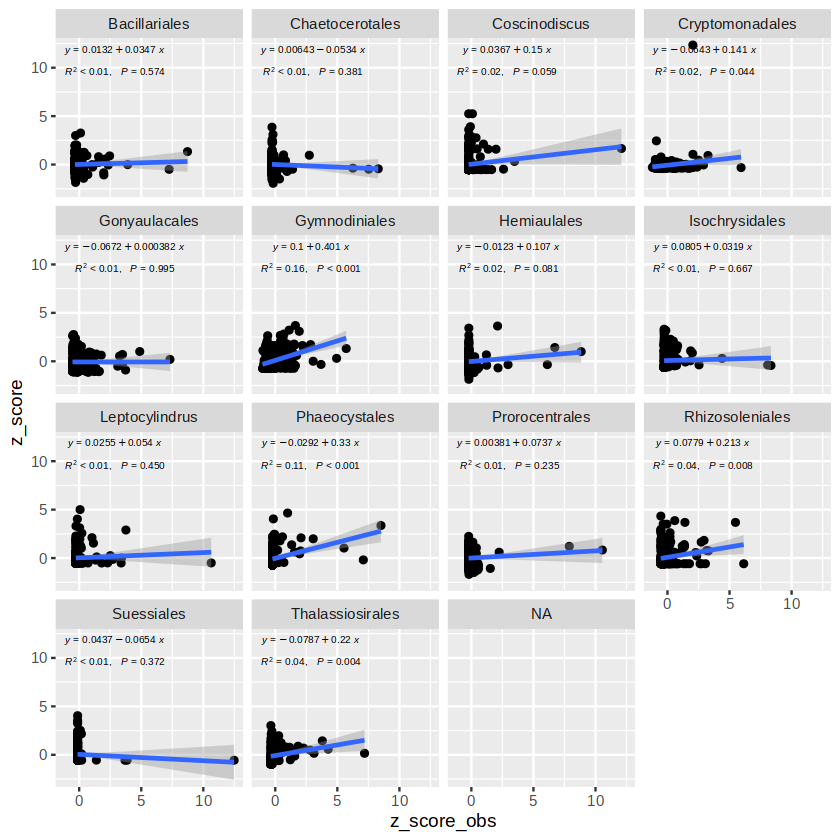

In [293]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type)

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_poly_eq()`).”
Warning message in ci_f_ncp(stat, df1 = df1, df2 = df2, probs = probs):
“Upper limit outside search range. Set to the maximum of the parameter range.”
Warning message in compute_group(...):
“CI computation error: Error in check_output(cint, probs = probs, parameter_range = c(0, 1)): out[1] <= out[2] is not TRUE
”
Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_point()`).”


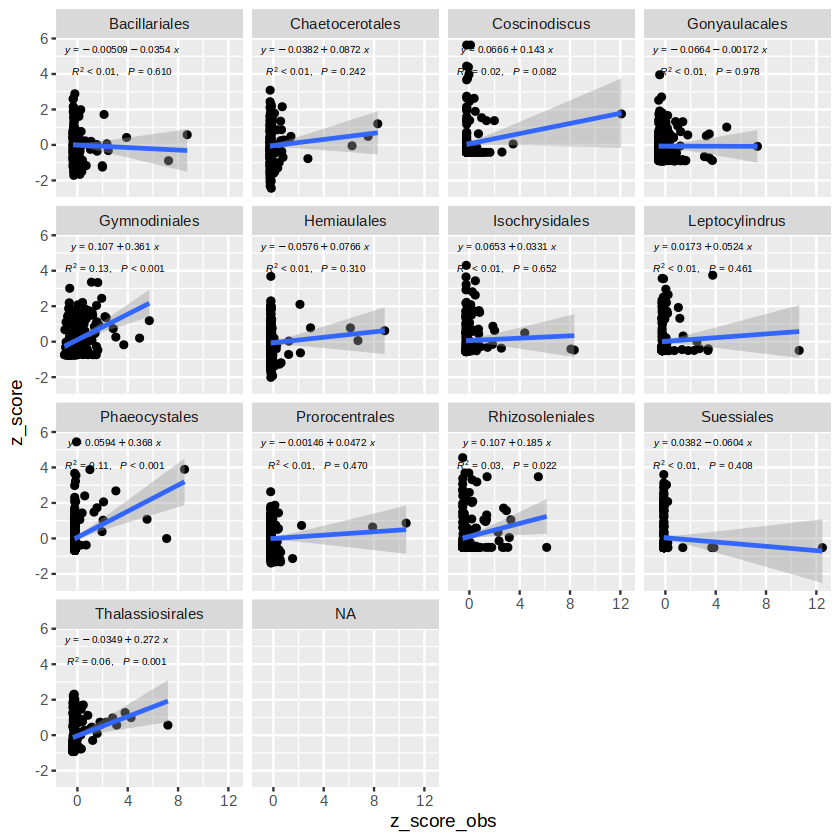

In [151]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type)

Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_line()`).”


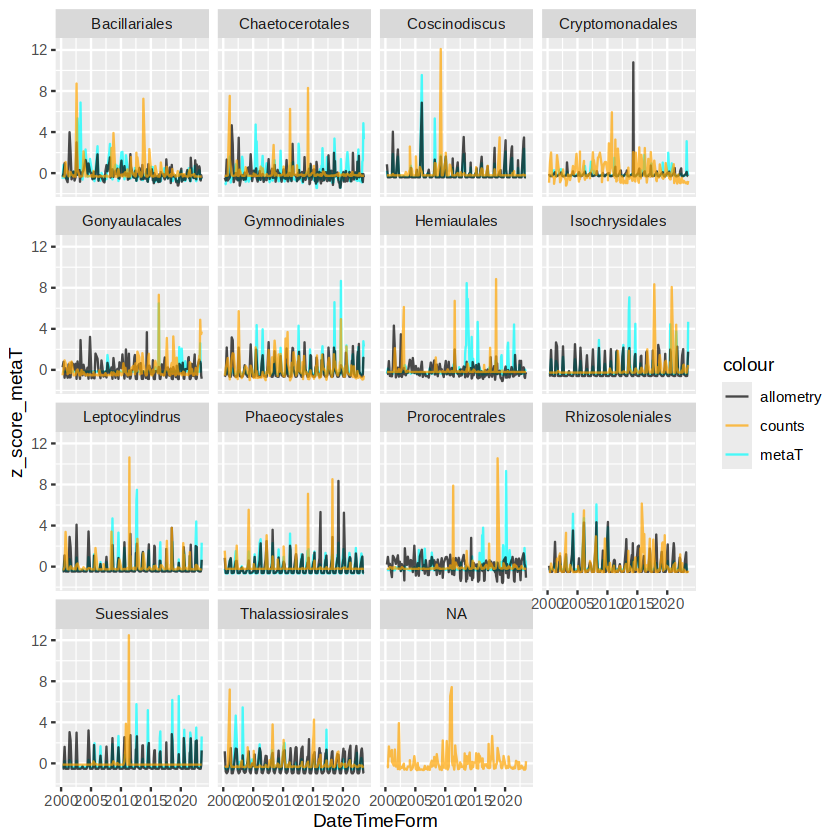

In [319]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::rename(c("abund_metaT"="abund","z_score_metaT"="z_score")) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::rename(c("abund_allometry"="abund","z_score_allometry"="z_score")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_line(aes(x=DateTimeForm,y=z_score_metaT,color="metaT"),alpha=0.7)+
    geom_line(aes(x=DateTimeForm,y=z_score_allometry,color="allometry"),alpha=0.7)+
    geom_line(aes(x=DateTimeForm,y=z_score_obs,color="counts"),alpha=0.7)+
    facet_wrap(~type) + 
    scale_color_manual(values=c("black","orange","cyan"))

In [324]:
for_spearman = for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d"))

results_fr = data.frame()
for (taxon in unique(for_spearman$type)) {
    if (is.na(taxon)) {
        next
    }
    for_spearman_sub = for_spearman %>% dplyr::filter(type==taxon)
    spearman_test = cor.test(for_spearman_sub$abund, for_spearman_sub$Group_Ct, method = "pearson")
    rho_val = spearman_test$estimate
    p_val = spearman_test$p.value
    results_fr = results_fr %>%
        dplyr::bind_rows(data.frame("taxon"=taxon,
                                    "rho"=rho_val,
                                    "pval"=p_val,
                                    "dataset"="allometry"))
}
results_fr$pval_adj = p.adjust(results_fr$pval, method = "BH", n = length(results_fr_2$pval))

In [325]:
for_spearman = for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d"))

results_fr_2 = data.frame()
for (taxon in unique(for_spearman$type)) {
    if (is.na(taxon)) {
        next
    }
    for_spearman_sub = for_spearman %>% dplyr::filter(type==taxon)
    spearman_test = cor.test(for_spearman_sub$abund, for_spearman_sub$Group_Ct, method = "pearson")
    rho_val = spearman_test$estimate
    p_val = spearman_test$p.value
    results_fr_2 = results_fr_2 %>%
        dplyr::bind_rows(data.frame("taxon"=taxon,
                                    "rho"=rho_val,
                                    "pval"=p_val,
                                    "dataset"="metaT"))
}

results_fr_2$pval_adj = p.adjust(results_fr_2$pval, method = "BH",
                                 n = length(results_fr_2$pval))

results_fr = results_fr %>% dplyr::bind_rows(results_fr_2)

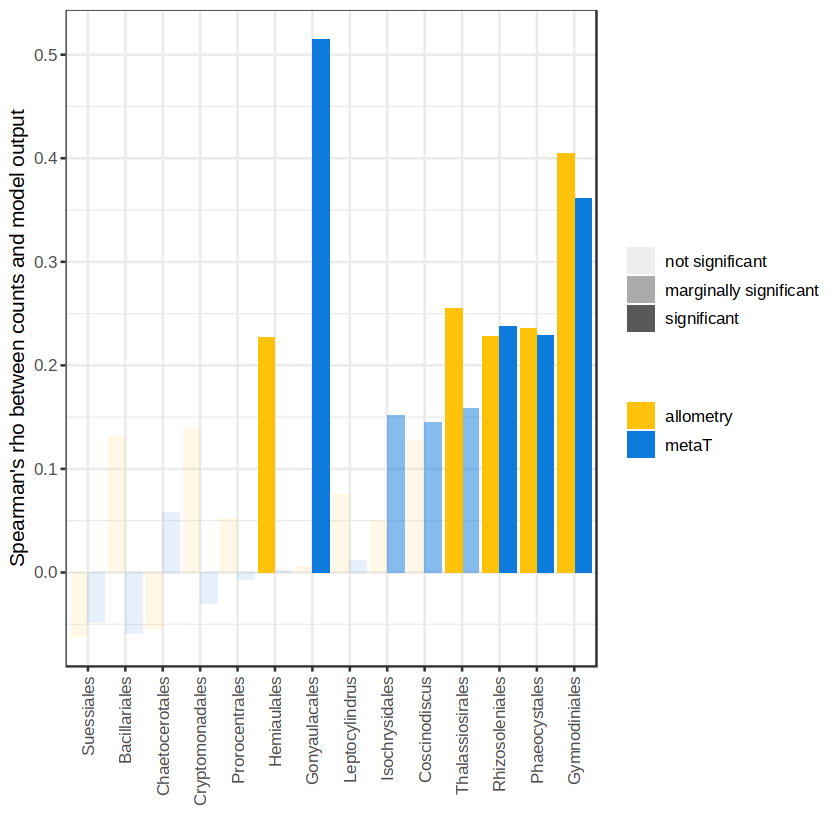

In [326]:
for_bar = results_fr %>% dplyr::arrange(taxon,desc(rho)) %>% 
    dplyr::mutate(rho_sig = case_when(pval_adj > 0.1 ~ 0,
                                      TRUE ~ rho)) %>%
    dplyr::mutate(pval_sig = case_when(pval_adj < 0.05 ~ "significant",
                                       pval_adj < 0.10 ~ "marginally significant",
                                      TRUE ~ "not significant")) %>%
    dplyr::arrange(rho) 

ggplot(for_bar) + 
    geom_bar(aes(x=factor(taxon,levels=unique(taxon)),
                 y=rho,alpha=pval_sig,
                 fill=dataset,group=dataset),
             stat="identity",position="dodge")+  
    theme_bw(base_size=12) + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))+
    scale_alpha_manual(values=c(0.1,0.5,1),breaks=c("not significant",
                                                    "marginally significant",
                                                    "significant"),
                       name="") + 
    scale_fill_manual(values=c("#FFC20A","#0C7BDC"),name="") + 
    xlab("") + ylab("Spearman's rho between counts and model output")

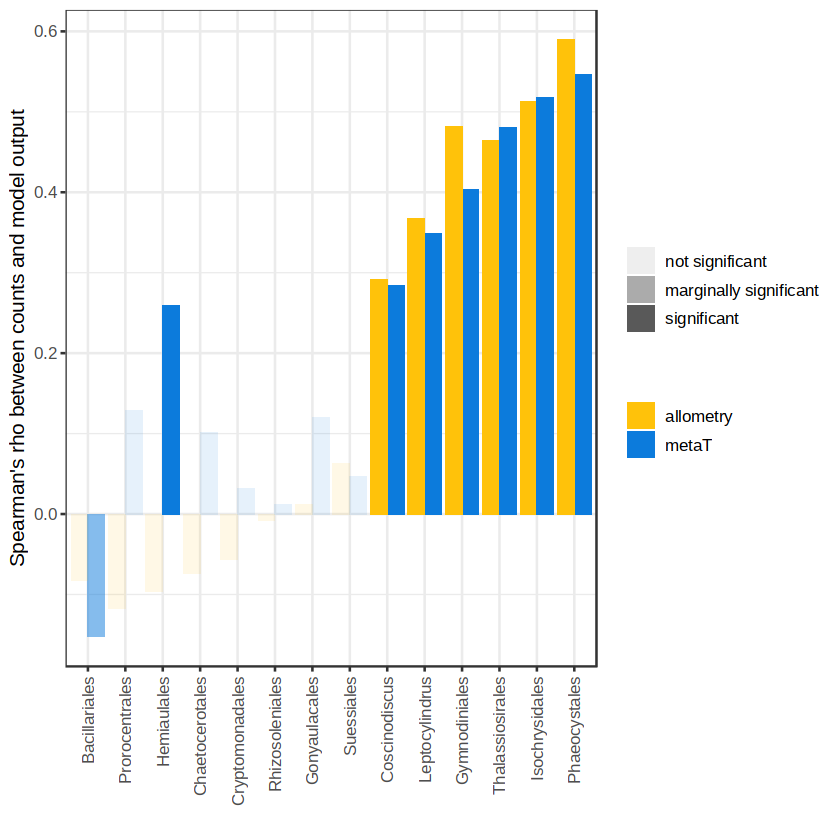

In [322]:
for_bar = results_fr %>% dplyr::arrange(taxon,desc(rho)) %>% 
    dplyr::mutate(rho_sig = case_when(pval_adj > 0.1 ~ 0,
                                      TRUE ~ rho)) %>%
    dplyr::mutate(pval_sig = case_when(pval_adj < 0.05 ~ "significant",
                                       pval_adj < 0.10 ~ "marginally significant",
                                      TRUE ~ "not significant")) %>%
    dplyr::arrange(rho) 

ggplot(for_bar) + 
    geom_bar(aes(x=factor(taxon,levels=unique(taxon)),
                 y=rho,alpha=pval_sig,
                 fill=dataset,group=dataset),
             stat="identity",position="dodge")+  
    theme_bw(base_size=12) + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))+
    scale_alpha_manual(values=c(0.1,0.5,1),breaks=c("not significant",
                                                    "marginally significant",
                                                    "significant"),
                       name="") + 
    scale_fill_manual(values=c("#FFC20A","#0C7BDC"),name="") + 
    xlab("") + ylab("Spearman's rho between counts and model output")

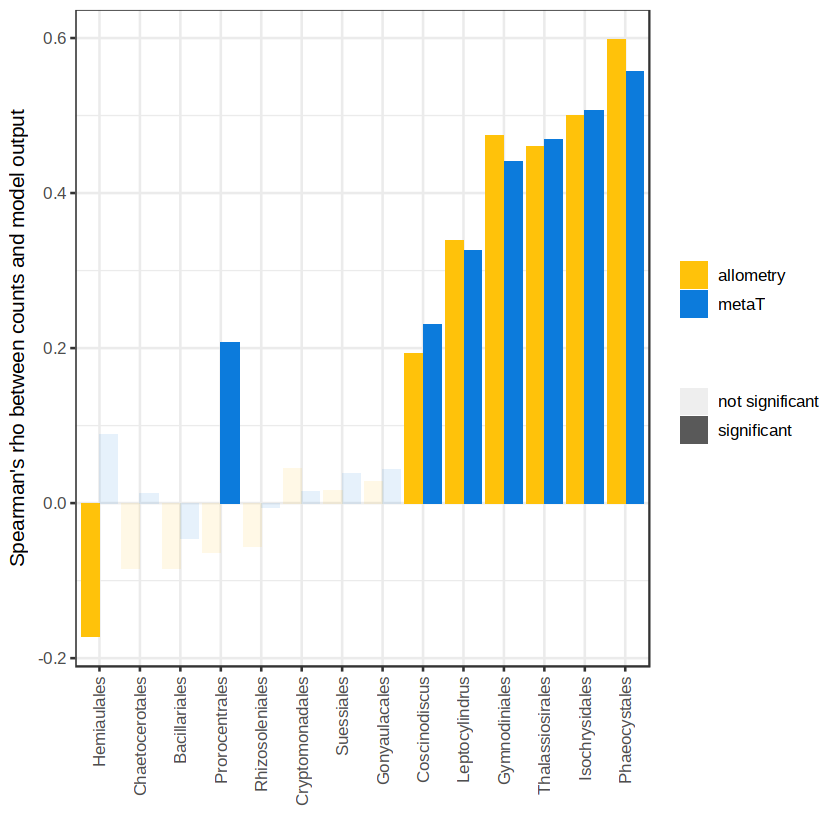

In [313]:
for_bar = results_fr %>% dplyr::arrange(taxon,desc(rho)) %>% 
    dplyr::mutate(rho_sig = case_when(pval_adj > 0.1 ~ 0,
                                      TRUE ~ rho)) %>%
    dplyr::mutate(pval_sig = case_when(pval_adj < 0.05 ~ "significant",
                                       pval_adj < 0.10 ~ "marginally significant",
                                      TRUE ~ "not significant")) %>%
    dplyr::arrange(rho) 

ggplot(for_bar) + 
    geom_bar(aes(x=factor(taxon,levels=unique(taxon)),
                 y=rho,alpha=pval_sig,
                 fill=dataset,group=dataset),
             stat="identity",position="dodge")+  
    theme_bw(base_size=12) + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))+
    scale_alpha_manual(values=c(0.1,0.5,1),breaks=c("not significant",
                                                    "marginally significant",
                                                    "significant"),
                       name="") + 
    scale_fill_manual(values=c("#FFC20A","#0C7BDC"),name="") + 
    xlab("") + ylab("Spearman's rho between counts and model output")

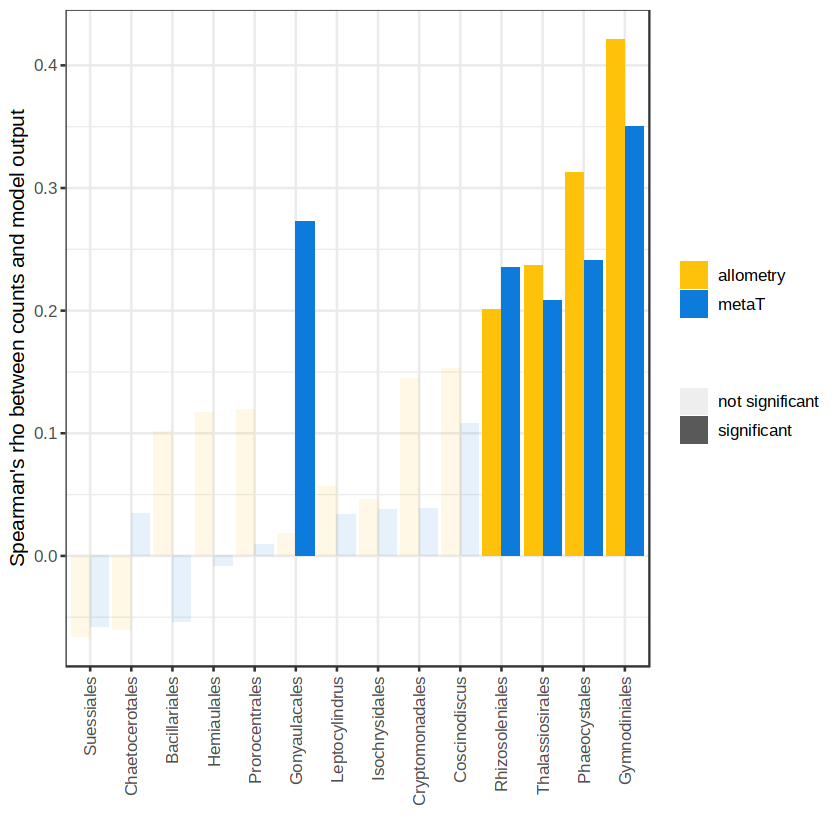

In [310]:
for_bar = results_fr %>% dplyr::arrange(taxon,desc(rho)) %>% 
    dplyr::mutate(rho_sig = case_when(pval_adj > 0.1 ~ 0,
                                      TRUE ~ rho)) %>%
    dplyr::mutate(pval_sig = case_when(pval_adj < 0.05 ~ "significant",
                                       pval_adj < 0.10 ~ "marginally significant",
                                      TRUE ~ "not significant")) %>%
    dplyr::arrange(rho) 

ggplot(for_bar) + 
    geom_bar(aes(x=factor(taxon,levels=unique(taxon)),
                 y=rho,alpha=pval_sig,
                 fill=dataset,group=dataset),
             stat="identity",position="dodge")+  
    theme_bw(base_size=12) + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))+
    scale_alpha_manual(values=c(0.1,0.5,1),breaks=c("not significant",
                                                    "marginally significant",
                                                    "significant"),
                       name="") + 
    scale_fill_manual(values=c("#FFC20A","#0C7BDC"),name="") + 
    xlab("") + ylab("Spearman's rho between counts and model output")

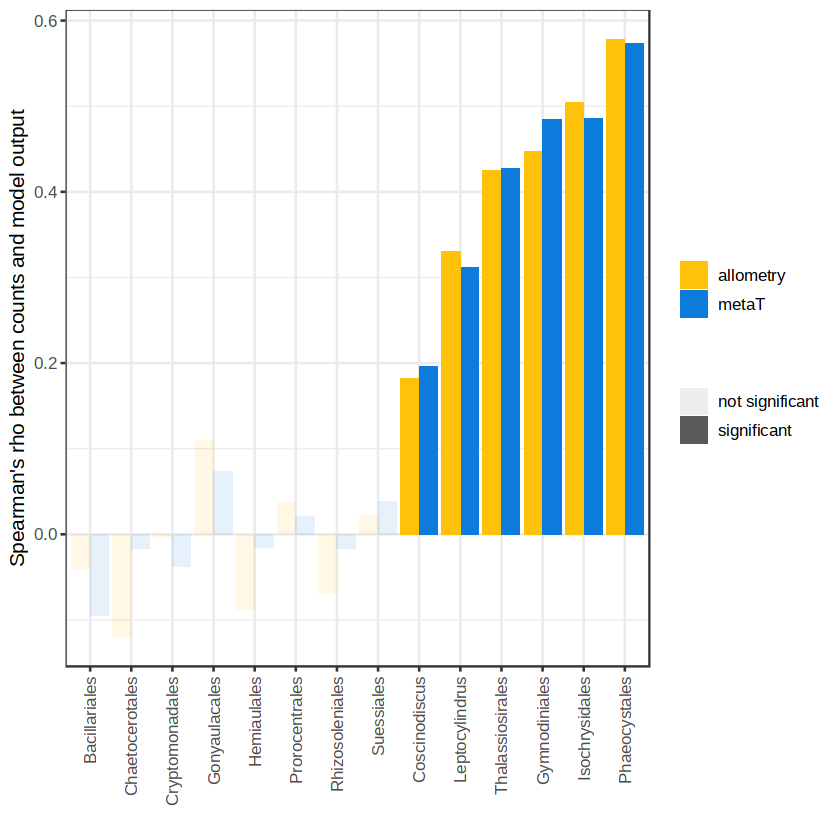

In [271]:
for_bar = results_fr %>% dplyr::arrange(taxon,desc(rho)) %>% 
    dplyr::mutate(rho_sig = case_when(pval_adj > 0.1 ~ 0,
                                      TRUE ~ rho)) %>%
    dplyr::mutate(pval_sig = case_when(pval_adj < 0.05 ~ "significant",
                                       pval_adj < 0.10 ~ "marginally significant",
                                      TRUE ~ "not significant")) %>%
    dplyr::arrange(rho_sig) 

ggplot(for_bar) + 
    geom_bar(aes(x=factor(taxon,levels=unique(taxon)),
                 y=rho,alpha=pval_sig,
                 fill=dataset,group=dataset),
             stat="identity",position="dodge")+  
    theme_bw(base_size=12) + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))+
    scale_alpha_manual(values=c(0.1,0.5,1),breaks=c("not significant",
                                                    "marginally significant",
                                                    "significant"),
                       name="") + 
    scale_fill_manual(values=c("#FFC20A","#0C7BDC"),name="") + 
    xlab("") + ylab("Spearman's rho between counts and model output")

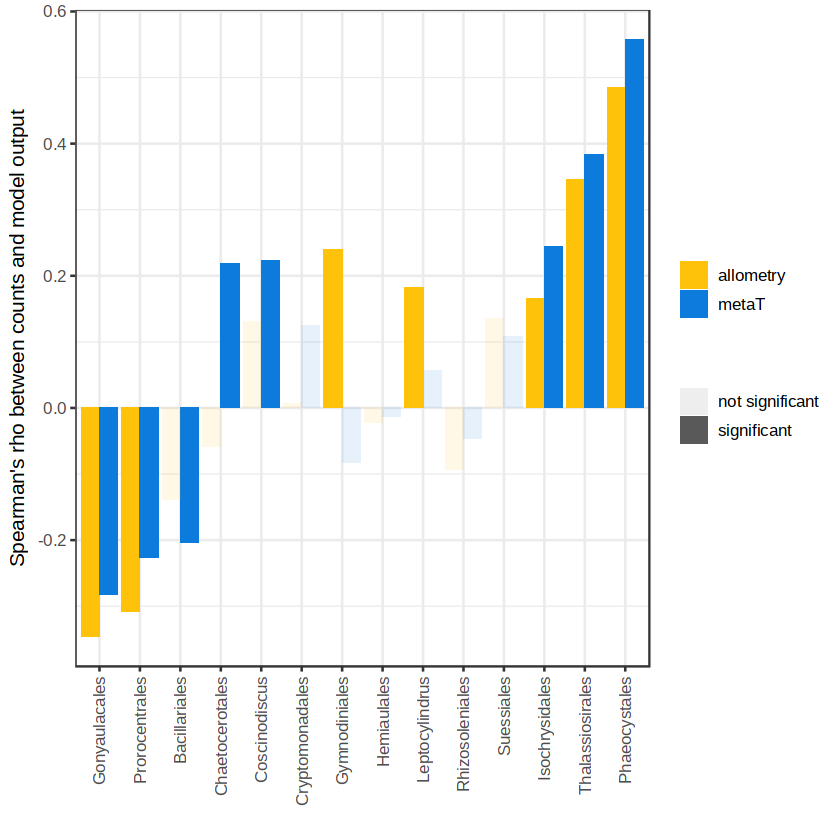

In [248]:
for_bar = results_fr %>% dplyr::arrange(taxon,desc(rho)) %>% 
    dplyr::mutate(rho_sig = case_when(pval_adj > 0.1 ~ 0,
                                      TRUE ~ rho)) %>%
    dplyr::mutate(pval_sig = case_when(pval_adj < 0.05 ~ "significant",
                                       pval_adj < 0.10 ~ "marginally significant",
                                      TRUE ~ "not significant")) %>%
    dplyr::arrange(rho_sig) 

ggplot(for_bar) + 
    geom_bar(aes(x=factor(taxon,levels=unique(taxon)),
                 y=rho,alpha=pval_sig,
                 fill=dataset,group=dataset),
             stat="identity",position="dodge")+  
    theme_bw(base_size=12) + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))+
    scale_alpha_manual(values=c(0.1,0.5,1),breaks=c("not significant",
                                                    "marginally significant",
                                                    "significant"),
                       name="") + 
    scale_fill_manual(values=c("#FFC20A","#0C7BDC"),name="") + 
    xlab("") + ylab("Spearman's rho between counts and model output")

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_poly_eq()`).”
Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_point()`).”


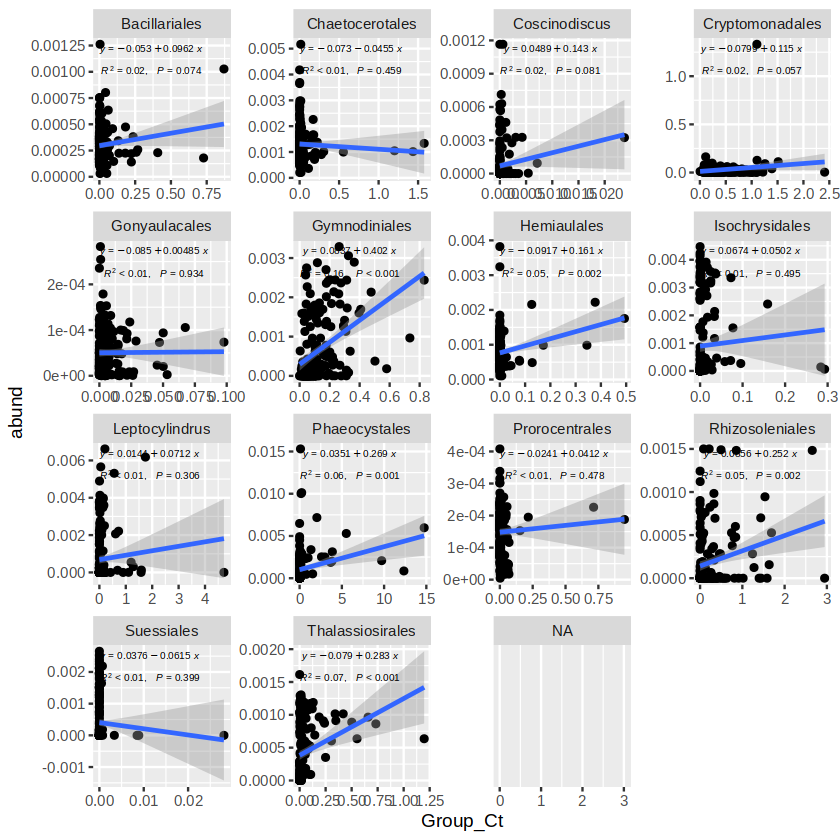

In [327]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=Group_Ct,y=abund))+
    geom_smooth(aes(x=Group_Ct,y=abund,group=type),method="lm")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type,scales="free")

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_poly_eq()`).”
Warning message in ci_f_ncp(stat, df1 = df1, df2 = df2, probs = probs):
“Upper limit outside search range. Set to the maximum of the parameter range.”
Warning message in compute_group(...):
“CI computation error: Error in check_output(cint, probs = probs, parameter_range = c(0, 1)): out[1] <= out[2] is not TRUE
”
Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_point()`).”


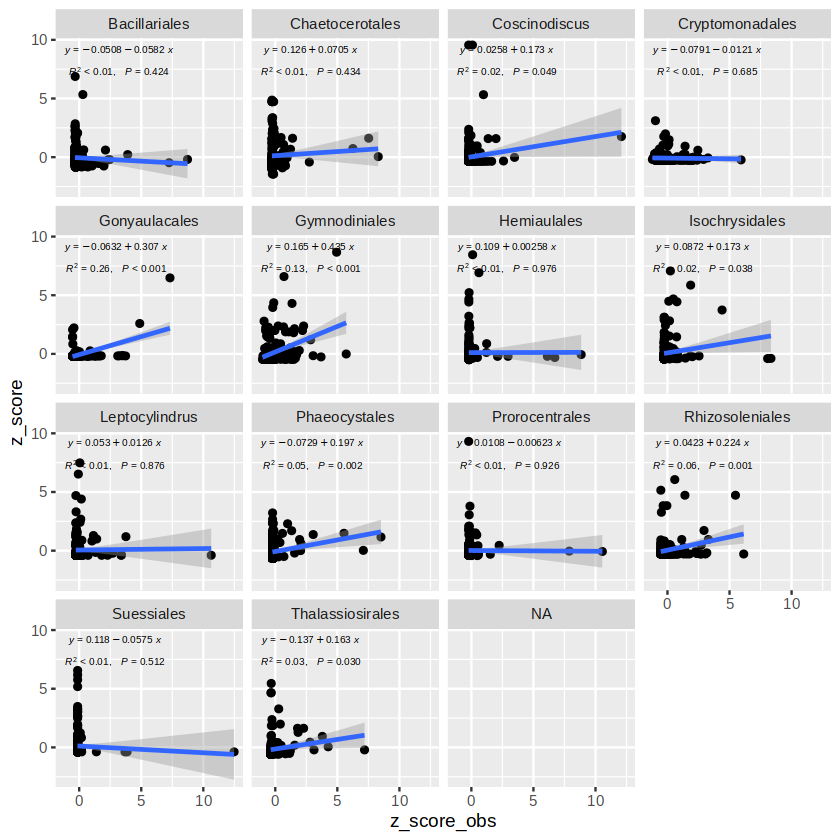

In [328]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type)

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_poly_eq()`).”
Warning message in ci_f_ncp(stat, df1 = df1, df2 = df2, probs = probs):
“Upper limit outside search range. Set to the maximum of the parameter range.”
Warning message in compute_group(...):
“CI computation error: Error in check_output(cint, probs = probs, parameter_range = c(0, 1)): out[1] <= out[2] is not TRUE
”
Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_point()`).”


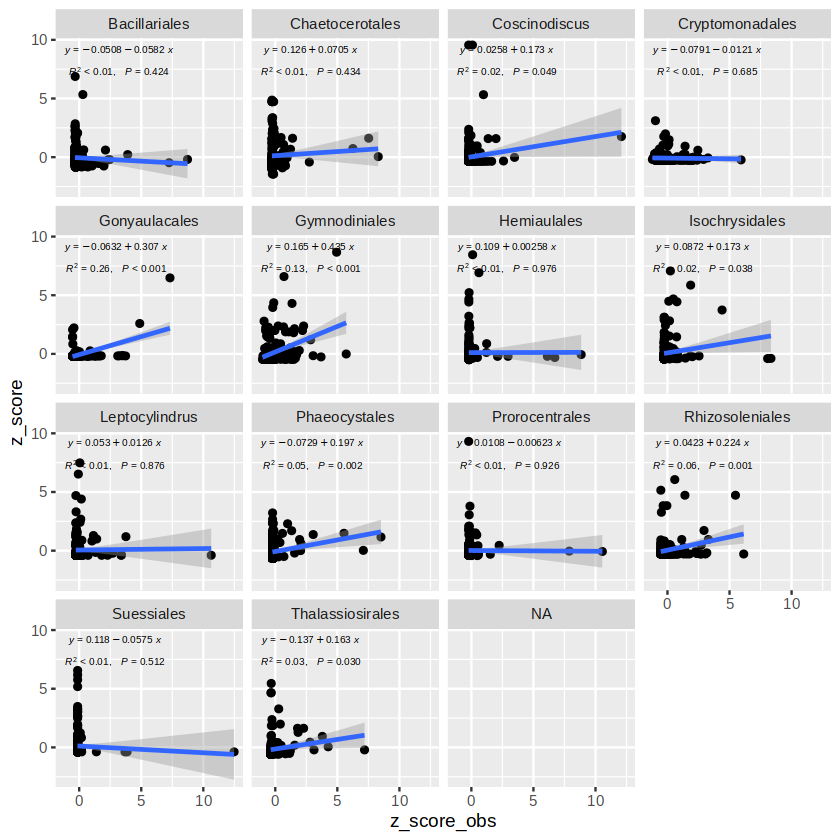

In [329]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type)

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


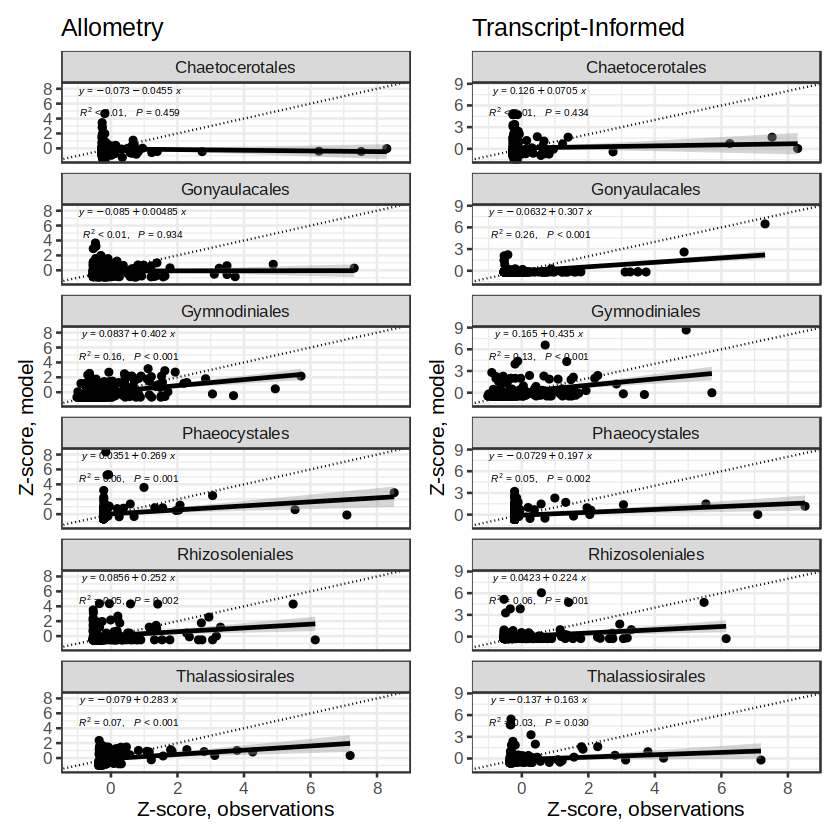

In [330]:
allometry=ggplot(for_prob_test%>%
    dplyr::filter(type %in% c("Chaetocerotales","Coscinodiscales",
                              "Gonyaulacales","Gymnodiniales",
                              "Phaeocystales","Rhizosoleniales",
                              "Thalassiosirales")) %>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm",color="black")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type,ncol=1) + theme_bw(base_size=12) + 
    geom_abline(aes(intercept=0,slope=1),linetype="dotted")+
    ylab("Z-score, model") + xlab("Z-score, observations") + 
    ggtitle("Allometry")

metaT=ggplot(for_prob_test%>%
    dplyr::filter(type %in% c("Chaetocerotales","Coscinodiscales",
                              "Gonyaulacales","Gymnodiniales",
                              "Phaeocystales","Rhizosoleniales",
                              "Thalassiosirales")) %>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm",color="black")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type,ncol=1) + theme_bw(base_size=12) + 
    geom_abline(aes(intercept=0,slope=1),linetype="dotted")+
    ylab("Z-score, model") + xlab("Z-score, observations") + 
    ggtitle("Transcript-Informed")

combo_plot = allometry | metaT
combo_plot
#ggsave(plot=combo_plot+plot_annotation(tag_levels = 'A'),width=9,height=10,units="in",filename="../figures/combined_model_results.pdf")

`geom_smooth()` using formula = 'y ~ x'
Warning message in ci_f_ncp(stat, df1 = df1, df2 = df2, probs = probs):
“Upper limit outside search range. Set to the maximum of the parameter range.”
Warning message in compute_group(...):
“CI computation error: Error in check_output(cint, probs = probs, parameter_range = c(0, 1)): out[1] <= out[2] is not TRUE
”
`geom_smooth()` using formula = 'y ~ x'


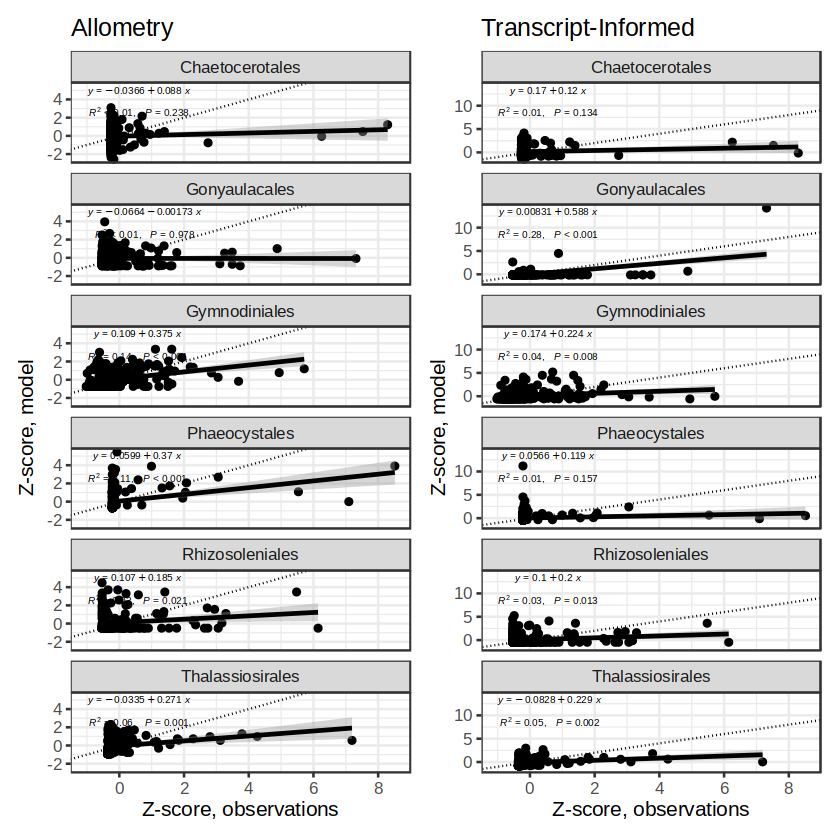

In [10]:
allometry=ggplot(for_prob_test%>%
    dplyr::filter(type %in% c("Chaetocerotales","Coscinodiscales",
                              "Gonyaulacales","Gymnodiniales",
                              "Phaeocystales","Rhizosoleniales",
                              "Thalassiosirales")) %>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm",color="black")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type,ncol=1) + theme_bw(base_size=12) + 
    geom_abline(aes(intercept=0,slope=1),linetype="dotted")+
    ylab("Z-score, model") + xlab("Z-score, observations") + 
    ggtitle("Allometry")

metaT=ggplot(for_prob_test%>%
    dplyr::filter(type %in% c("Chaetocerotales","Coscinodiscales",
                              "Gonyaulacales","Gymnodiniales",
                              "Phaeocystales","Rhizosoleniales",
                              "Thalassiosirales")) %>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm",color="black")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type,ncol=1) + theme_bw(base_size=12) + 
    geom_abline(aes(intercept=0,slope=1),linetype="dotted")+
    ylab("Z-score, model") + xlab("Z-score, observations") + 
    ggtitle("Transcript-Informed")

combo_plot = allometry | metaT
combo_plot
#ggsave(plot=combo_plot+plot_annotation(tag_levels = 'A'),width=9,height=10,units="in",filename="../figures/combined_model_results.pdf")

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


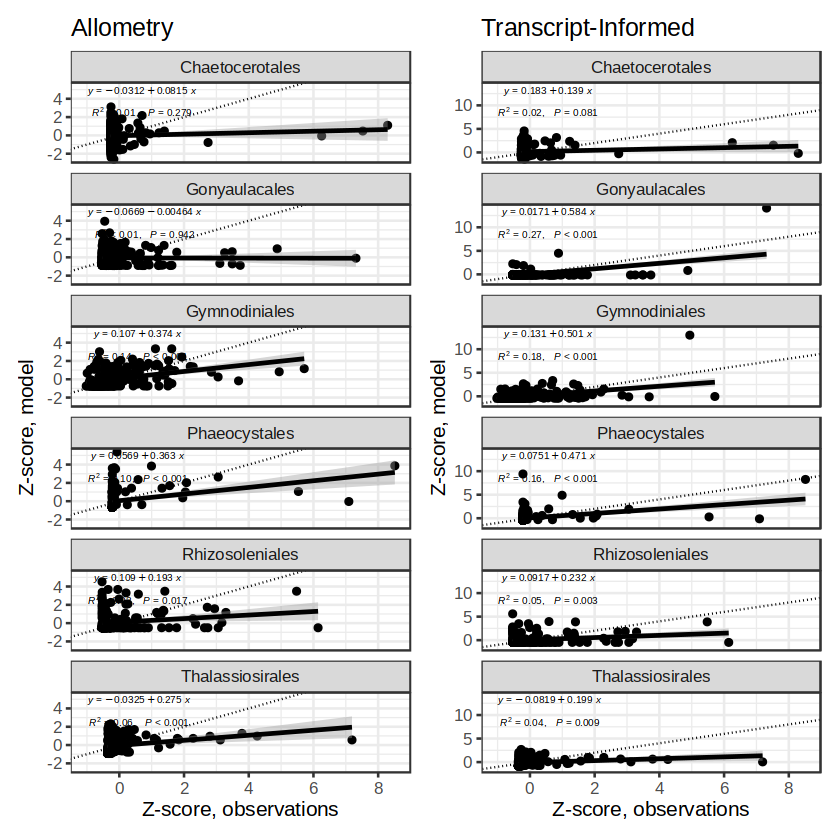

In [206]:
allometry=ggplot(for_prob_test%>%
    dplyr::filter(type %in% c("Chaetocerotales","Coscinodiscales",
                              "Gonyaulacales","Gymnodiniales",
                              "Phaeocystales","Rhizosoleniales",
                              "Thalassiosirales")) %>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm",color="black")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type,ncol=1) + theme_bw(base_size=12) + 
    geom_abline(aes(intercept=0,slope=1),linetype="dotted")+
    ylab("Z-score, model") + xlab("Z-score, observations") + 
    ggtitle("Allometry")

metaT=ggplot(for_prob_test%>%
    dplyr::filter(type %in% c("Chaetocerotales","Coscinodiscales",
                              "Gonyaulacales","Gymnodiniales",
                              "Phaeocystales","Rhizosoleniales",
                              "Thalassiosirales")) %>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm",color="black")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type,ncol=1) + theme_bw(base_size=12) + 
    geom_abline(aes(intercept=0,slope=1),linetype="dotted")+
    ylab("Z-score, model") + xlab("Z-score, observations") + 
    ggtitle("Transcript-Informed")

combo_plot = allometry | metaT
combo_plot
#ggsave(plot=combo_plot+plot_annotation(tag_levels = 'A'),width=9,height=10,units="in",filename="../figures/combined_model_results.pdf")

In [161]:
allometry=ggplot(for_prob_test%>%
    dplyr::filter(type %in% c("Chaetocerotales","Coscinodiscales",
                              "Gonyaulacales","Gymnodiniales",
                              "Phaeocystales","Rhizosoleniales",
                              "Thalassiosirales")) %>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm",color="black")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type,ncol=1) + theme_bw(base_size=12) + 
    geom_abline(aes(intercept=0,slope=1),linetype="dotted")+
    ylab("Z-score, model") + xlab("Z-score, observations") + 
    ggtitle("Allometry")

metaT=ggplot(for_prob_test%>%
    dplyr::filter(type %in% c("Chaetocerotales","Coscinodiscales",
                              "Gonyaulacales","Gymnodiniales",
                              "Phaeocystales","Rhizosoleniales",
                              "Thalassiosirales")) %>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm",color="black")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type,ncol=1) + theme_bw(base_size=12) + 
    geom_abline(aes(intercept=0,slope=1),linetype="dotted")+
    ylab("Z-score, model") + xlab("Z-score, observations") + 
    ggtitle("Transcript-Informed")

combo_plot = allometry | metaT

ggsave(plot=combo_plot+plot_annotation(tag_levels = 'A'),width=9,height=10,units="in",filename="../figures/combined_model_results.pdf")

`geom_smooth()` using formula = 'y ~ x'
Warning message in ci_f_ncp(stat, df1 = df1, df2 = df2, probs = probs):
“Upper limit outside search range. Set to the maximum of the parameter range.”
Warning message in compute_group(...):
“CI computation error: Error in check_output(cint, probs = probs, parameter_range = c(0, 1)): out[1] <= out[2] is not TRUE
”
`geom_smooth()` using formula = 'y ~ x'


In [155]:
bacillariales_events = for_prob_test %>% dplyr::filter(type=="Bacillariales") %>%
    dplyr::mutate(high_event=case_when(Group_Ct > 0.05~"high",
                  TRUE~"low"),
                 year=year(Date)) %>%
    dplyr::filter(year>2007)%>%
    dplyr::group_by(high_event,year) %>% dplyr::tally() %>%
    dplyr::arrange(year) %>% tidyr::pivot_wider(id_cols = c("year"),
                                         names_from="high_event",
                                         values_from="n") %>%
    dplyr::mutate(high=case_when(is.na(high)~0,
                                 TRUE~high))

mk.test(bacillariales_events$high)


	Mann-Kendall trend test

data:  bacillariales_events$high
z = -2.1938, n = 16, p-value = 0.02825
alternative hypothesis: true S is not equal to 0
sample estimates:
          S        varS         tau 
-47.0000000 439.6666667  -0.4547914 


In [59]:
thalassiosirales_events = for_prob_test %>% dplyr::filter(type=="Thalassiosirales") %>%
    dplyr::mutate(high_event=case_when(Group_Ct > 0.25~"high",
                  TRUE~"low"),
                 year=year(Date)) %>%
    dplyr::group_by(high_event,year) %>% dplyr::tally() %>%
    dplyr::arrange(year) %>% tidyr::pivot_wider(id_cols = c("year"),
                                         names_from="high_event",
                                         values_from="n") %>%
    dplyr::mutate(high=case_when(is.na(high)~0,
                                 TRUE~high))

mk.test(thalassiosirales_events$high,alternative = "less")


	Mann-Kendall trend test

data:  thalassiosirales_events$high
z = -1.9872, n = 24, p-value = 0.02345
alternative hypothesis: true S is less than 0
sample estimates:
          S        varS         tau 
-61.0000000 911.6666667  -0.3454109 


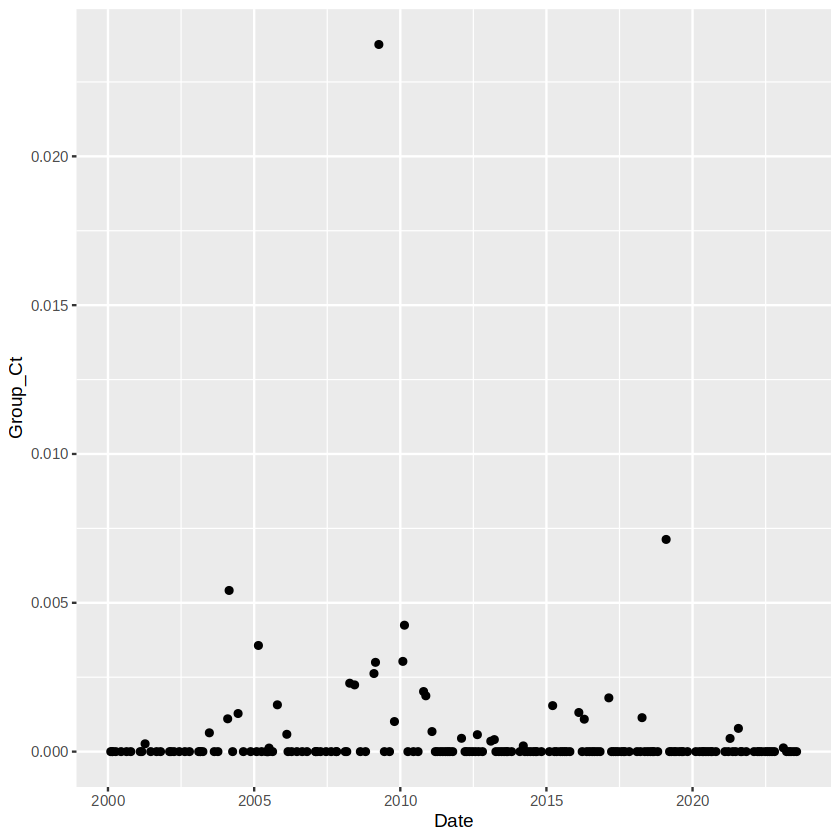

In [61]:
ggplot(for_prob_test %>% dplyr::filter(type=="Coscinodiscus"))+
    geom_point(aes(x=Date,y=Group_Ct))

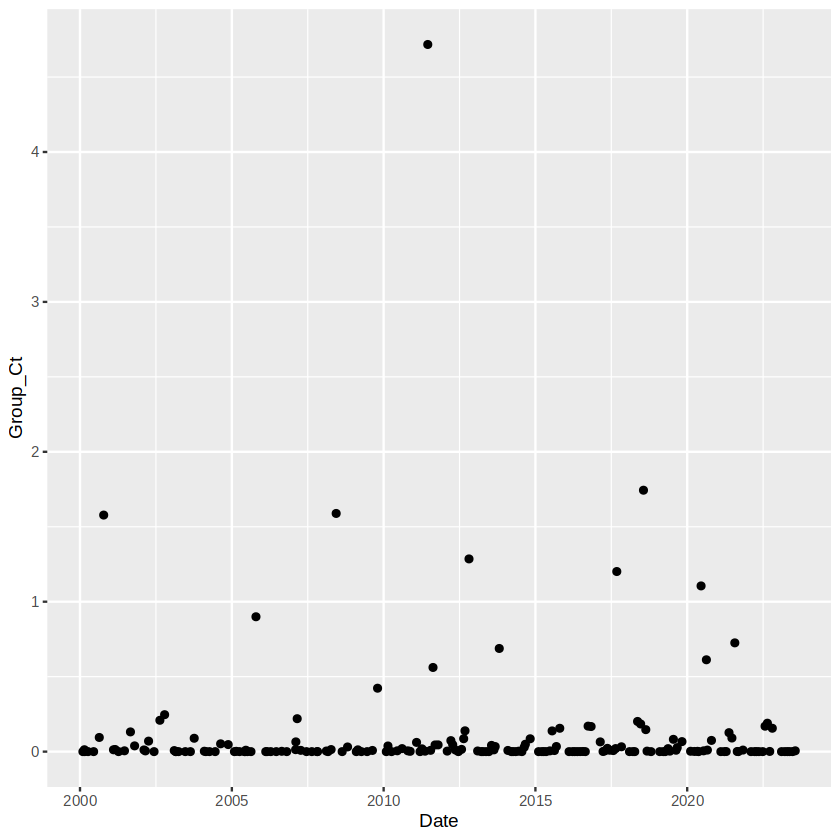

In [49]:
ggplot(for_prob_test %>% dplyr::filter(type=="Leptocylindrus"))+
    geom_point(aes(x=Date,y=Group_Ct))

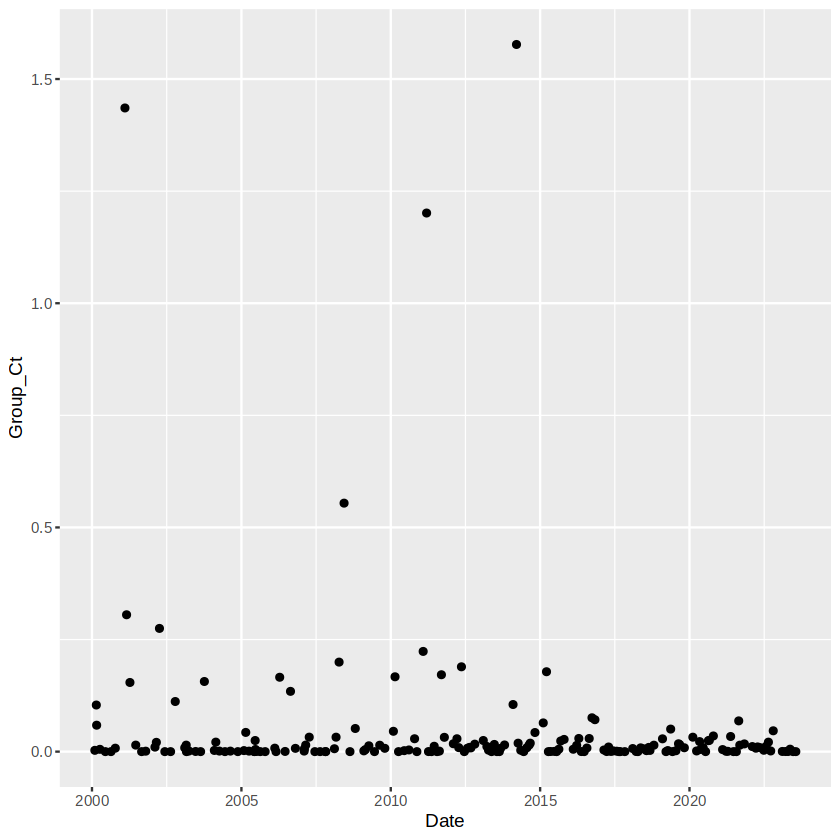

In [50]:
ggplot(for_prob_test %>% dplyr::filter(type=="Chaetocerotales"))+
    geom_point(aes(x=Date,y=Group_Ct))

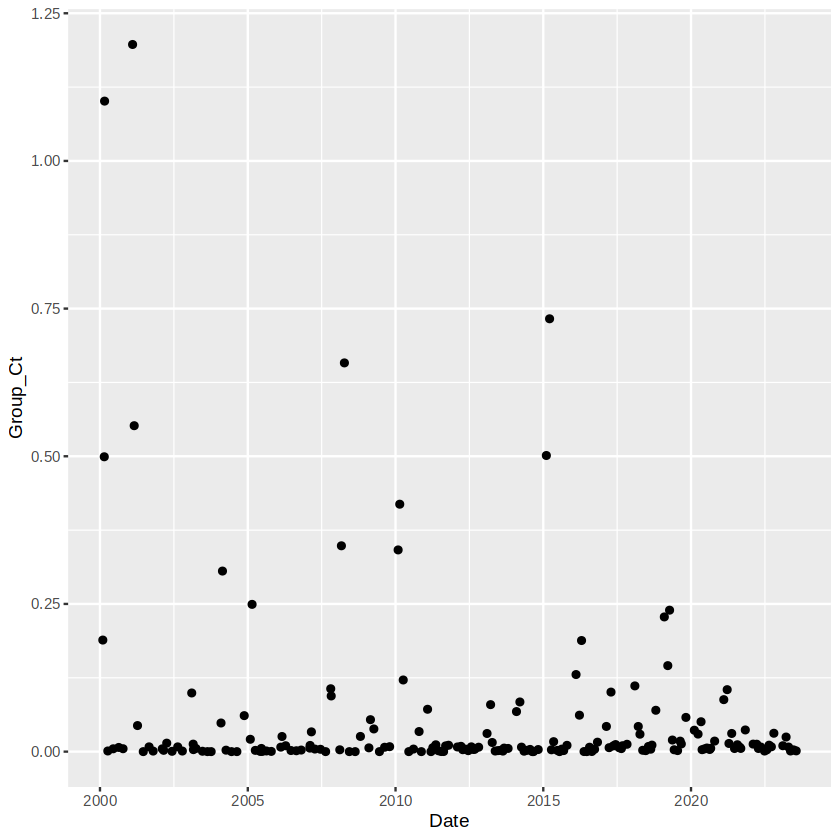

In [52]:
ggplot(for_prob_test %>% dplyr::filter(type=="Thalassiosirales"))+
    geom_point(aes(x=Date,y=Group_Ct))

In [47]:
unique(for_prob_test$type)

[1] "Bacillariales"    "Chaetocerotales"  "Coccolithophore"  "Coscinodiscus"   
 [5] "Gymnodiniales"    "Hemiaulales"      "Leptocylindrus"   "Phaeocystales"   
 [9] "Prorocentrum"     "Rhizosoleniales"  "Suessiales"       "Thalassiosirales"
[13] NA

In [62]:
all_stats


,statistic,organism,p_value,total_abundance,avg_abundance
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
z...1,1.6699580,Bacillariales,4.746384e-02,6.18073393,0.0325301786
z...2,-0.1365418,Chaetocerotales,5.543035e-01,9.23393035,0.0485996334
z...3,6.3867804,Coccolithophore,8.470732e-11,1.72305016,0.0090686850
z...4,-1.6068063,Coscinodiscus,9.459516e-01,0.07864522,0.0004139222
z...5,-0.8375182,Gymnodiniales,7.988493e-01,23.93679976,0.1259831566
z...6,-0.9242205,Hemiaulales,8.223142e-01,2.10065642,0.0110560864
z...7,0.7315114,Leptocylindrus,2.322334e-01,21.89418322,0.1152325433
z...8,1.0381393,Phaeocystales,1.496026e-01,69.32647242,0.3648761706
z...9,4.7101114,Prorocentrum,1.237907e-06,3.61765198,0.0190402736


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type and Date.
ℹ Output is grouped by type.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(type, Date))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


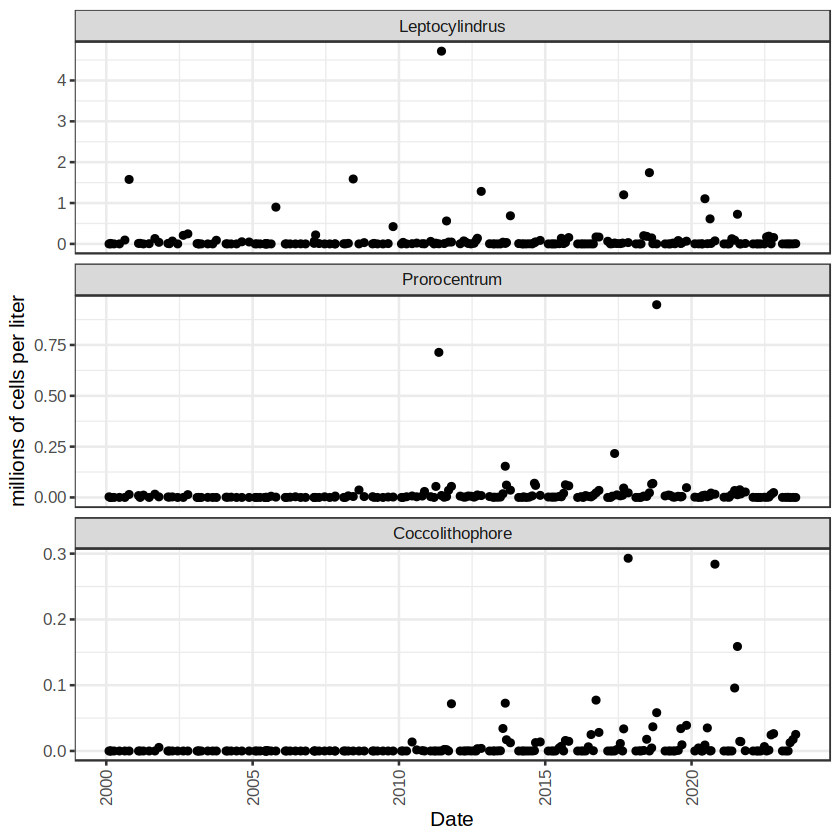

In [9]:
for_plotting = infill_dates %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus")) %>%
    dplyr::group_by(type,Date) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore")))) + 
    geom_point(aes(x=Date,y=Group_Ct)) + 
    theme_bw(base_size=12) + facet_wrap(~type,nrow=3,scales="free_y") +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends

In [59]:
## read in nutrient data
nutrient_data = read.csv(file.path("../data/CC_wet_chemistry_2022_2023.csv")) %>%
    dplyr::bind_rows(read.csv(file.path("../data/CC_wet_chemistry_2000_2021.csv")))

In [60]:
processed_df = nutrient_data %>% 
    dplyr::filter(DEPTH<5)%>%dplyr::filter(STAT_ID%in%c("F01","F02","F29"))%>%
    dplyr::filter(PARAM_CODE%in% c("NO2","NO3","NO3+NO2","CHLA","PO4","SIO4"))%>%
    dplyr::mutate(Category=case_when(PARAM_CODE %in% c("NO2","NO3","NO3+NO2")~"Nitrogen",
                                     PARAM_CODE %in% c("CHLA")~"Chlorophyll",
                                     TRUE~"Phosphorus")) %>%
    dplyr::mutate(Year = year(as.Date(STAT_ARRIV,format='%d-%b-%Y %H:%M:%S')),
                  Date=as.Date(STAT_ARRIV,format='%d-%b-%Y %H:%M:%S'))

In [38]:
unique(paired_data$GROUP_ID)

[1] "CHRYSOPHYTES"      "CENTRIC DIATOM"    "PENNATE DIATOM"   
 [4] "PRASINOPHYTES"     "DINOFLAGELLATES"   "CRYPTOPHYTES"     
 [7] "MICROFLAGELLATES"  "EUGLENOPHYTES"     "HAPTOPHYTES"      
[10] "CILIOPHORA_HETERO" "CILIATEA"          "DINOFLAG_HETERO"  
[13] "RAPHIDOPHYTE"      "CHLOROPHYTES"      NA

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type, Date, and STAT_ID.
ℹ Output i

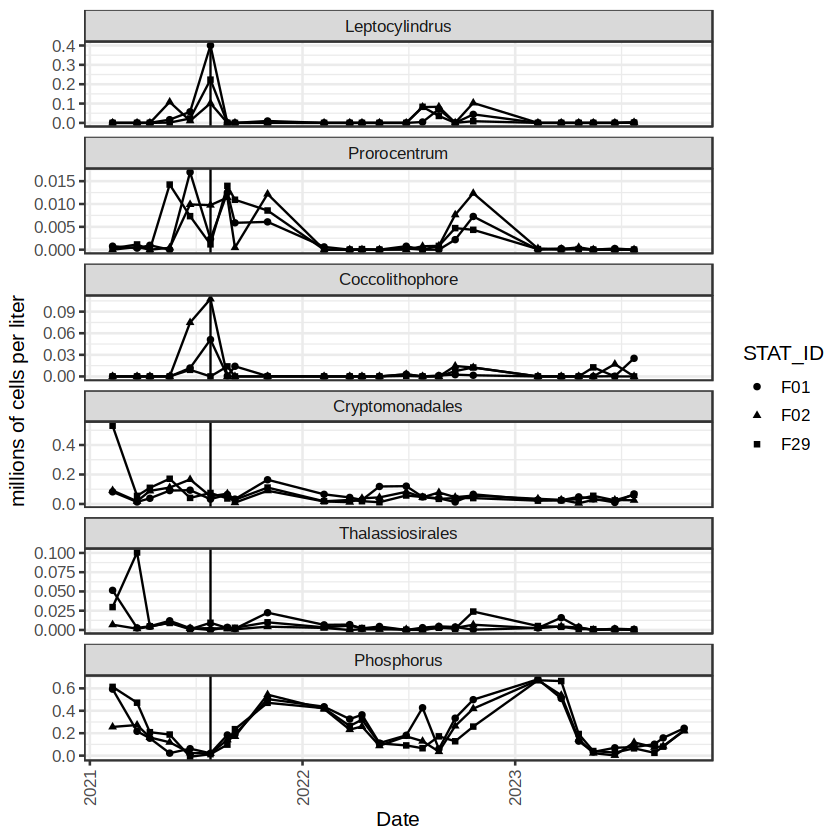

In [20]:
infill_dates_crypto = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM","PRASINOPHYTES",
                                        "PENNATE DIATOM","DINOFLAGELLATES","CRYPTOPHYTES")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date","STAT_ID"),names_from="DESCR",values_from="Group_Ct")

infill_dates_crypto[is.na(infill_dates_crypto)]=0

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")|
                               starts_with("STAT_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)|grepl("Thalassios",DESCR)|grepl("Cryptomonas",DESCR)|
                  grepl("Chilomonas",DESCR)|grepl("Hemiselmis",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales")) %>%
    dplyr::group_by(type,Date,STAT_ID) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

infill_dates_tot = infill_dates_crypto  %>% 
    tidyr::pivot_longer(cols=!starts_with("Date")& !starts_with("STAT_ID"),
                        names_to = "organism", values_to="counts")  %>%
    dplyr::group_by(STAT_ID,Date) %>%
    dplyr::summarize(total_counts=sum(counts))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(infill_dates_tot) %>%
    dplyr::mutate(Scaled_Ct = Group_Ct) %>% # / total_counts) %>%
    dplyr::bind_rows(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("type"="Category","Scaled_Ct"="FFU_RESULT")))%>%
    dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore",
                                            "Cryptomonadales",
                                            "Thalassiosirales",
                                            "Phosphorus")))) + 
    geom_point(aes(x=Date,y=Scaled_Ct,shape=STAT_ID)) +  
    geom_line(aes(x=Date,y=Scaled_Ct,group=STAT_ID)) + 
    geom_vline(aes(xintercept=as.Date("2021-07-27",format="%Y-%m-%d"))) + 
    theme_bw(base_size=12) + facet_wrap(~type,scales="free_y",ncol=1) +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends
#ggsave("../figures/abundances_w_phosphate.pdf")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type, Date, and STAT_ID.
ℹ Output i

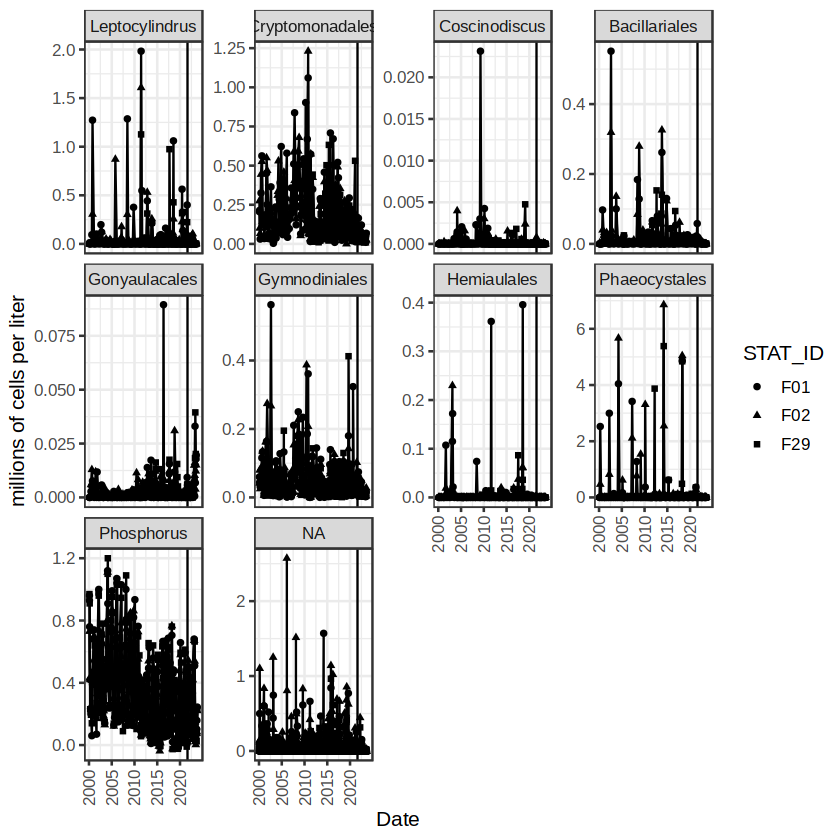

In [61]:

infill_dates_crypto = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES","CRYPTOPHYTES")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date","STAT_ID"),names_from="DESCR",values_from="Group_Ct")

infill_dates_crypto[is.na(infill_dates_crypto)]=0

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")|
                               starts_with("STAT_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|
                                 grepl("Emiliania",DESCR)|
                                 grepl("Isochrysis",DESCR)~"Isochrysidales",
                                 grepl("Prorocentru",DESCR)~"Prorocentrales",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales",
                                 grepl("nitzschia",tolower(DESCR))|
                                 grepl("Bacillaria",DESCR)|
                                 grepl("Cylindrotheca",DESCR)|
                                 grepl("Fragilariopsis",DESCR)|
                                 grepl("Denticula",DESCR)~"Bacillariales",
                                 grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)~
                                 "Prymesiophyte",
                                 grepl("Hemiaulus",DESCR)|grepl("Eucampia",DESCR)|
                                 grepl("Cerataulina",DESCR)~
                                 "Hemiaulales",
                                 grepl("Coscino",DESCR)~
                                 "Coscinodiscus",
                                 grepl("Gymnodinium",DESCR)|grepl("Gyrodinium",DESCR)|
                                 grepl("Karenia",DESCR)|grepl("Amphidinium",DESCR)|
                                 grepl("Akashiwo",DESCR)~
                                 "Gymnodiniales",
                                 grepl("Guinardia",DESCR)|grepl("Proboscia",DESCR)|
                                 grepl("Dactyliosolen",DESCR)|grepl("Rhizosolenia",DESCR)~
                                 "Rhizosoleniales",
                                 grepl("Thecate",DESCR)~
                                 "Suessiales",
                                 grepl("Gonyaulax",DESCR)|grepl("ceratium",tolower(DESCR))|
                                 grepl("Tripos",DESCR)~
                                 "Gonyaulacales",
                                 grepl("Chaetocero",DESCR)~"Chaetocerotales",
                                 grepl("Phaeo",DESCR)~
                                 "Phaeocystales")) %>%
    dplyr::filter(!is.na(type)) %>%
    dplyr::group_by(type,Date,STAT_ID) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

infill_dates_tot = infill_dates_crypto  %>% 
    tidyr::pivot_longer(cols=!starts_with("Date")& !starts_with("STAT_ID"),
                        names_to = "organism", values_to="counts")  %>%
    dplyr::group_by(STAT_ID,Date) %>%
    dplyr::summarize(total_counts=sum(counts))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(infill_dates_tot) %>%
    dplyr::mutate(Scaled_Ct = Group_Ct) %>% # / total_counts) %>%
    dplyr::bind_rows(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("type"="Category","Scaled_Ct"="FFU_RESULT")))%>%
    #dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore",
                                            "Cryptomonadales",
                                            "Coscinodiscus",
                                            "Bacillariales",
                                            "Gonyaulacales",
                                            "Gymnodiniales",
                                            "Hemiaulales",
                                            "Phaeocystales",
                                            "Phosphorus")))) + 
    geom_point(aes(x=Date,y=Scaled_Ct,shape=STAT_ID)) +  
    geom_line(aes(x=Date,y=Scaled_Ct,group=STAT_ID)) + 
    geom_vline(aes(xintercept=as.Date("2021-07-27",format="%Y-%m-%d"))) + 
    theme_bw(base_size=12) + facet_wrap(~type,scales="free_y") +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends
#ggsave("../figures/abundances_w_phosphate.pdf")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type, Date, and STAT_ID.
ℹ Output i

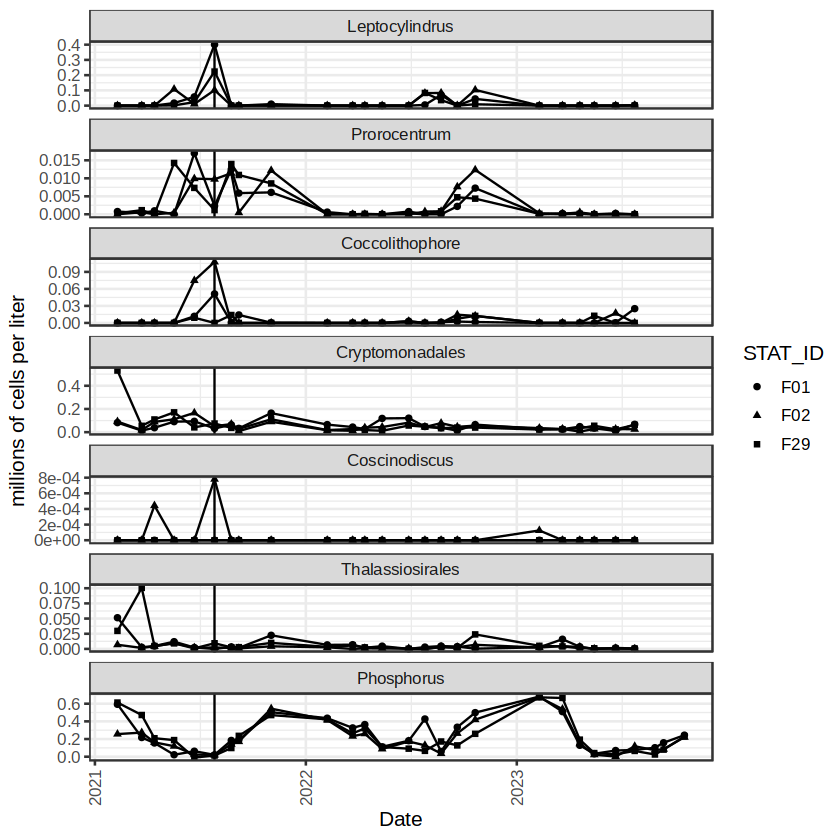

In [21]:
infill_dates_crypto = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES","CRYPTOPHYTES")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date","STAT_ID"),names_from="DESCR",values_from="Group_Ct")

infill_dates_crypto[is.na(infill_dates_crypto)]=0

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")|
                               starts_with("STAT_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)|grepl("Thalassios",DESCR)|grepl("Cryptomonas",DESCR)|
                  grepl("Chilomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                  grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)|grepl("Coscino",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales",
                                 grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)~
                                 "Prymesiophyte",
                                 grepl("Coscino",DESCR)~
                                 "Coscinodiscus")) %>%
    dplyr::group_by(type,Date,STAT_ID) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

infill_dates_tot = infill_dates_crypto  %>% 
    tidyr::pivot_longer(cols=!starts_with("Date")& !starts_with("STAT_ID"),
                        names_to = "organism", values_to="counts")  %>%
    dplyr::group_by(STAT_ID,Date) %>%
    dplyr::summarize(total_counts=sum(counts))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(infill_dates_tot) %>%
    dplyr::mutate(Scaled_Ct = Group_Ct) %>% # / total_counts) %>%
    dplyr::bind_rows(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("type"="Category","Scaled_Ct"="FFU_RESULT")))%>%
    dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore",
                                            "Cryptomonadales",
                                            "Coscinodiscus",
                                            "Thalassiosirales",
                                            "Prymesiophyte",
                                            "Phosphorus")))) + 
    geom_point(aes(x=Date,y=Scaled_Ct,shape=STAT_ID)) +  
    geom_line(aes(x=Date,y=Scaled_Ct,group=STAT_ID)) + 
    geom_vline(aes(xintercept=as.Date("2021-07-27",format="%Y-%m-%d"))) + 
    theme_bw(base_size=12) + facet_wrap(~type,scales="free_y",ncol=1) +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends
#ggsave("../figures/abundances_w_phosphate.pdf")

In [24]:
unique(paired_data$DESCR)

[1] "Dictyocha speculum"                                                   
  [2] "Corethron criophilum"                                                 
  [3] "Skeletonema costatum species complex"                                 
  [4] "Thalassiosira nordenskioeldii"                                        
  [5] "Thalassiosira sp. group 3 10-20 microns length"                       
  [6] "Chaetoceros sp. group 1 diam <10 microns"                             
  [7] "Rhizosolenia setigera"                                                
  [8] "Guinardia delicatula"                                                 
  [9] "Centric diatom sp. group 1 diam <10 microns"                          
 [10] "Thalassionema nitzschioides"                                          
 [11] "Pleurosigma spp."                                                     
 [12] "Pennate diatom sp. group 2 10-30 microns length"                      
 [13] "Pennate diatom sp. group 3 31-60 microns length"                      
 [14] "Pyramimonas sp. group 1 10-20 microns length"                         
 [15] "Prorocentrum micans"                                                  
 [16] "Gymnodinium sp. group 1 5-20 microns width, 10-20 microns length"     
 [17] "Gymnodinium sp. group 2 21-40 microns width, 21-50 microns length"    
 [18] "Gyrodinium spirale"                                                   
 [19] "Cryptomonas sp. group 1 length <10 microns"                           
 [20] "Cryptomonas sp. group 2 length >10 microns"                           
 [21] "Unid. micro-phytoflag sp. group 1 length <10 microns"                 
 [22] "Unid. micro-phytoflag sp. group 2 length >10 microns"                 
 [23] "Ebria tripartita"                                                     
 [24] "Chaetoceros sp. group 2 diam 10-30 microns"                           
 [25] "Cylindrotheca closterium"                                             
 [26] "Eutreptia/Eutreptiella spp."                                          
 [27] "Gyrodinium sp. group 1 5-20 microns width, 10-20 microns length"      
 [28] "Heterocapsa rotundata"                                                
 [29] "Protoperidinium bipes"                                                
 [30] "Leptocylindrus minimus"                                               
 [31] "Thalassiosira rotula"                                                 
 [32] "Chaetoceros debilis"                                                  
 [33] "Choanoflagellate"                                                     
 [34] "Chaetoceros decipiens"                                                
 [35] "Chaetoceros socialis"                                                 
 [36] "Protoperidinium sp. group 1 10-30 microns width, 10-40 microns length"
 [37] "Thalassiosira anguste-lineata"                                        
 [38] "Thalassiosira sp. group 4 20-30 microns length"                       
 [39] "Detonula confervacea"                                                 
 [40] "Chaetoceros didymus"                                                  
 [41] "Stephanopyxis turris"                                                 
 [42] "Chaetoceros diadema"                                                  
 [43] "Asterionellopsis glacialis"                                           
 [44] "Phaeocystis pouchetii"                                                
 [45] "Paulinella ovalis"                                                    
 [46] "Prorocentrum minimum"                                                 
 [47] "Dinophysis norvegica"                                                 
 [48] "Gyrodinium sp. group 2 21-40 microns width, 21-50 microns length"     
 [49] "Protoperidinium brevipes"                                             
 [50] "Ceratium fusus"                                                       
 [51] "Calycomonas wulffii"                                                  
 [52] "Ceratium lineatum

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type, Date, and STAT_ID.
ℹ Output i

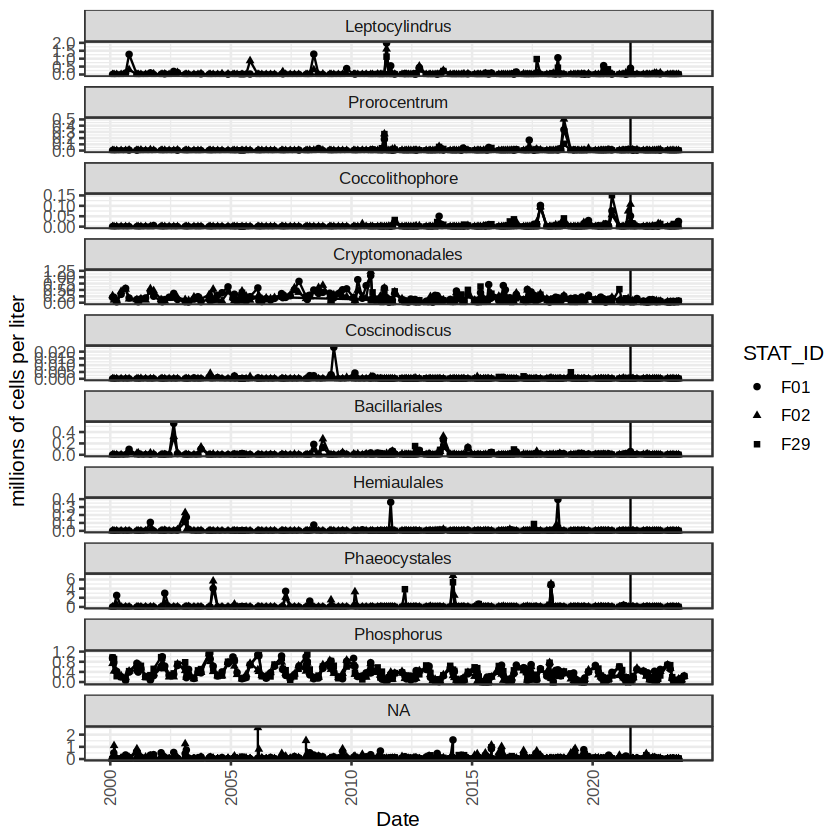

In [19]:
infill_dates_crypto = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES","CRYPTOPHYTES")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date","STAT_ID"),names_from="DESCR",values_from="Group_Ct")

infill_dates_crypto[is.na(infill_dates_crypto)]=0

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")|
                               starts_with("STAT_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)|grepl("Thalassios",DESCR)|grepl("Cryptomonas",DESCR)|
                  grepl("Chilomonas",DESCR)|grepl("Hemiselmis",DESCR)|grepl("Hemiaulus",DESCR)|
                  grepl("Eucampia",DESCR)|grepl("Cerataulina",DESCR)|
                  grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)|
                  grepl("Gymnodinium",DESCR)|grepl("Gyrodinium",DESCR)|
                  grepl("Karenia",DESCR)|
                  grepl("Guinardia",DESCR)|
                  grepl("Proboscia",DESCR)|
                  grepl("Dactyliosolen",DESCR)|
                  grepl("Rhizosolenia",DESCR)|
                  grepl("Thecate",DESCR)|
                 grepl("nitzschia",tolower(DESCR))|
                 grepl("Bacillaria",DESCR)|
                 grepl("Cylindrotheca",DESCR)|
                 grepl("Fragilariopsis",DESCR)|
                 grepl("Denticula",DESCR)|
                  grepl("Phaeo",DESCR)|
                  grepl("Chaeto",DESCR)|
                  grepl("Coscino",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales",
                                 grepl("nitzschia",tolower(DESCR))|
                                 grepl("Bacillaria",DESCR)|
                                 grepl("Cylindrotheca",DESCR)|
                                 grepl("Fragilariopsis",DESCR)|
                                 grepl("Denticula",DESCR)~"Bacillariales",
                                 grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)~
                                 "Prymesiophyte",
                                 grepl("Hemiaulus",DESCR)|grepl("Eucampia",DESCR)|
                                 grepl("Cerataulina",DESCR)~
                                 "Hemiaulales",
                                 grepl("Coscino",DESCR)~
                                 "Coscinodiscus",
                                 grepl("Gymnodinium",DESCR)|grepl("Gyrodinium",DESCR)|
                                 grepl("Karenia",DESCR)~
                                 "Gymnodiniales",
                                 grepl("Guinardia",DESCR)|grepl("Proboscia",DESCR)|
                                 grepl("Dactyliosolen",DESCR)|grepl("Rhizosolenia",DESCR)~
                                 "Rhizosoleniales",
                                 grepl("Thecate",DESCR)~
                                 "Suessiales",
                                 grepl("Chaetocero",DESCR)~"Chaetocerotales",
                                 grepl("Phaeo",DESCR)~
                                 "Phaeocystales")) %>%
    dplyr::group_by(type,Date,STAT_ID) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

infill_dates_tot = infill_dates_crypto  %>% 
    tidyr::pivot_longer(cols=!starts_with("Date")& !starts_with("STAT_ID"),
                        names_to = "organism", values_to="counts")  %>%
    dplyr::group_by(STAT_ID,Date) %>%
    dplyr::summarize(total_counts=sum(counts))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(infill_dates_tot) %>%
    dplyr::mutate(Scaled_Ct = Group_Ct) %>% # / total_counts) %>%
    dplyr::bind_rows(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("type"="Category","Scaled_Ct"="FFU_RESULT")))%>%
    #dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore",
                                            "Cryptomonadales",
                                            "Coscinodiscus",
                                            "Bacillariales",
                                            "Hemiaulales",
                                            "Phaeocystales",
                                            "Phosphorus")))) + 
    geom_point(aes(x=Date,y=Scaled_Ct,shape=STAT_ID)) +  
    geom_line(aes(x=Date,y=Scaled_Ct,group=STAT_ID)) + 
    geom_vline(aes(xintercept=as.Date("2021-07-27",format="%Y-%m-%d"))) + 
    theme_bw(base_size=12) + facet_wrap(~type,scales="free_y",ncol=1) +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends
#ggsave("../figures/abundances_w_phosphate.pdf")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type, Date, and STAT_ID.
ℹ Output i

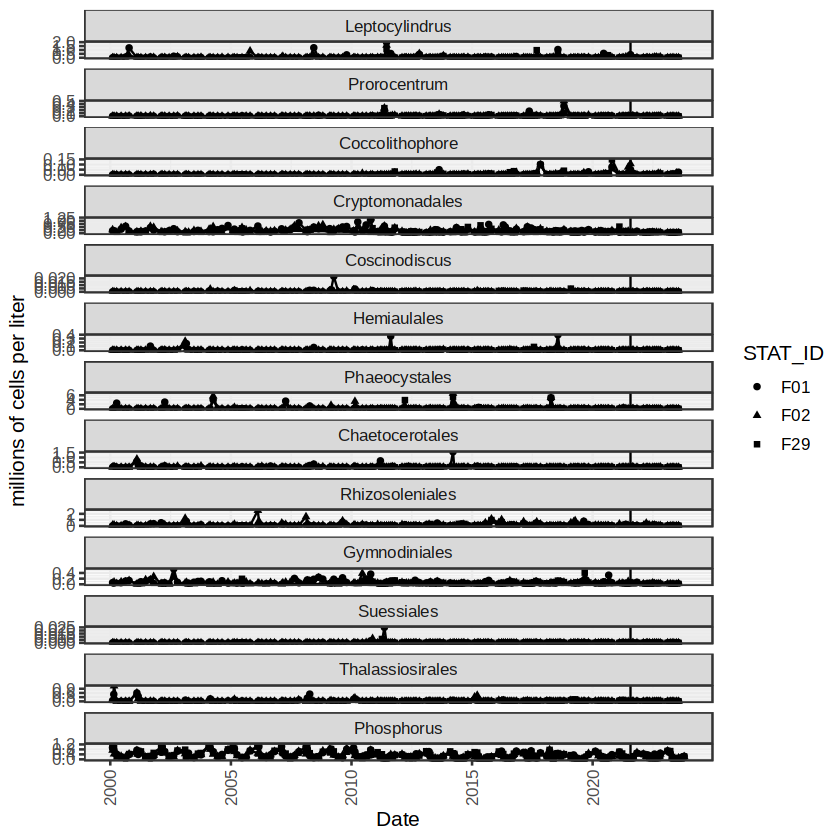

In [32]:
infill_dates_crypto = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES","CRYPTOPHYTES")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date","STAT_ID"),names_from="DESCR",values_from="Group_Ct")

infill_dates_crypto[is.na(infill_dates_crypto)]=0

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")|
                               starts_with("STAT_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)|grepl("Thalassios",DESCR)|grepl("Cryptomonas",DESCR)|
                  grepl("Chilomonas",DESCR)|grepl("Hemiselmis",DESCR)|grepl("Hemiaulus",DESCR)|
                  grepl("Eucampia",DESCR)|grepl("Cerataulina",DESCR)|
                  grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)|
                  grepl("Gymnodinium",DESCR)|grepl("Gyrodinium",DESCR)|
                  grepl("Karenia",DESCR)|
                  grepl("Guinardia",DESCR)|
                  grepl("Proboscia",DESCR)|
                  grepl("Dactyliosolen",DESCR)|
                  grepl("Rhizosolenia",DESCR)|
                  grepl("Thecate",DESCR)|
                  grepl("Phaeo",DESCR)|
                  grepl("Chaeto",DESCR)|
                  grepl("Coscino",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales",
                                 grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)~
                                 "Prymesiophyte",
                                 grepl("Hemiaulus",DESCR)|grepl("Eucampia",DESCR)|
                                 grepl("Cerataulina",DESCR)~
                                 "Hemiaulales",
                                 grepl("Coscino",DESCR)~
                                 "Coscinodiscus",
                                 grepl("Gymnodinium",DESCR)|grepl("Gyrodinium",DESCR)|
                                 grepl("Karenia",DESCR)~
                                 "Gymnodiniales",
                                 grepl("Guinardia",DESCR)|grepl("Proboscia",DESCR)|
                                 grepl("Dactyliosolen",DESCR)|grepl("Rhizosolenia",DESCR)~
                                 "Rhizosoleniales",
                                 grepl("Thecate",DESCR)~
                                 "Suessiales",
                                 grepl("Chaetocero",DESCR)~"Chaetocerotales",
                                 grepl("Phaeo",DESCR)~
                                 "Phaeocystales")) %>%
    dplyr::group_by(type,Date,STAT_ID) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

infill_dates_tot = infill_dates_crypto  %>% 
    tidyr::pivot_longer(cols=!starts_with("Date")& !starts_with("STAT_ID"),
                        names_to = "organism", values_to="counts")  %>%
    dplyr::group_by(STAT_ID,Date) %>%
    dplyr::summarize(total_counts=sum(counts))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(infill_dates_tot) %>%
    dplyr::mutate(Scaled_Ct = Group_Ct) %>% # / total_counts) %>%
    dplyr::bind_rows(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("type"="Category","Scaled_Ct"="FFU_RESULT")))%>%
    #dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore",
                                            "Cryptomonadales",
                                            "Coscinodiscus",
                                            "Hemiaulales",
                                            "Phaeocystales",
                                            "Chaetocerotales",
                                            "Rhizosoleniales",
                                            "Gymnodiniales",
                                            "Suessiales",
                                            "Thalassiosirales",
                                            "Prymesiophyte",
                                            "Phosphorus")))) + 
    geom_point(aes(x=Date,y=Scaled_Ct,shape=STAT_ID)) +  
    geom_line(aes(x=Date,y=Scaled_Ct,group=STAT_ID)) + 
    geom_vline(aes(xintercept=as.Date("2021-07-27",format="%Y-%m-%d"))) + 
    theme_bw(base_size=12) + facet_wrap(~type,scales="free_y",ncol=1) +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends
#ggsave("../figures/abundances_w_phosphate.pdf")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type, Date, and STAT_ID.
ℹ Output i

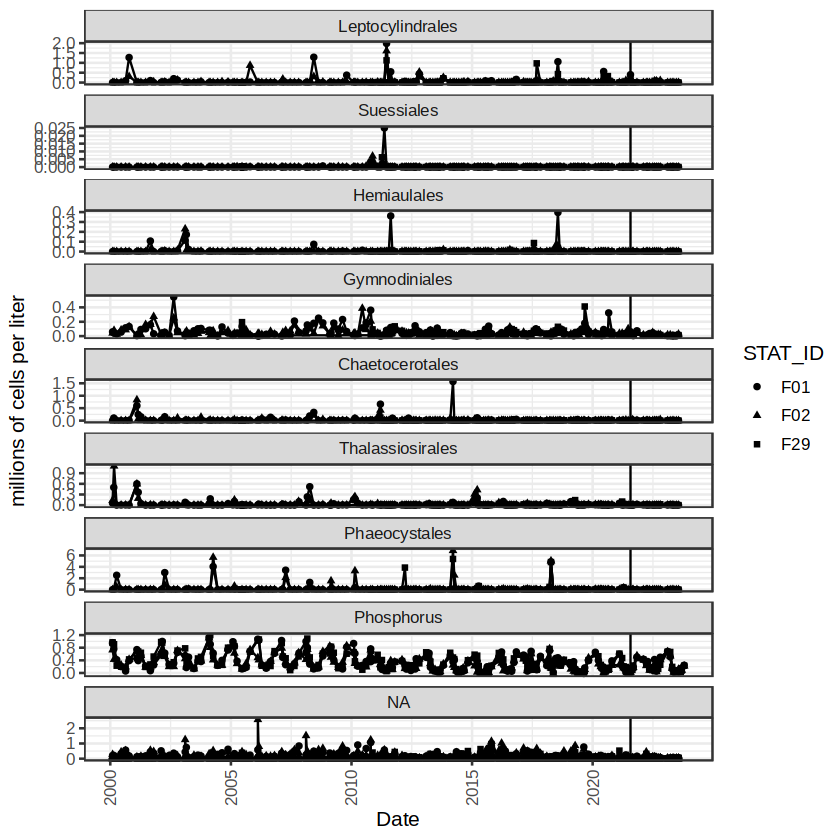

In [36]:
infill_dates_crypto = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES","CRYPTOPHYTES")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date","STAT_ID"),names_from="DESCR",values_from="Group_Ct")

infill_dates_crypto[is.na(infill_dates_crypto)]=0

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")|
                               starts_with("STAT_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)|grepl("Thalassios",DESCR)|grepl("Cryptomonas",DESCR)|
                  grepl("Chilomonas",DESCR)|grepl("Hemiselmis",DESCR)|grepl("Hemiaulus",DESCR)|
                  grepl("Eucampia",DESCR)|grepl("Cerataulina",DESCR)|
                  grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)|
                  grepl("Gymnodinium",DESCR)|grepl("Gyrodinium",DESCR)|
                  grepl("Karenia",DESCR)|
                  grepl("Guinardia",DESCR)|
                  grepl("Proboscia",DESCR)|
                  grepl("Dactyliosolen",DESCR)|
                  grepl("Rhizosolenia",DESCR)|
                  grepl("Phaeo",DESCR)|
                  grepl("Thecate",DESCR)|
                  grepl("Chaeto",DESCR)|
                  grepl("Coscino",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrales",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales",
                                 grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)~
                                 "Prymesiophyte",
                                 grepl("Hemiaulus",DESCR)|grepl("Eucampia",DESCR)|
                                 grepl("Cerataulina",DESCR)~
                                 "Hemiaulales",
                                 grepl("Coscino",DESCR)~
                                 "Coscinodiscus",
                                 grepl("Gymnodinium",DESCR)|grepl("Gyrodinium",DESCR)|
                                 grepl("Karenia",DESCR)~
                                 "Gymnodiniales",
                                 grepl("Guinardia",DESCR)|grepl("Proboscia",DESCR)|
                                 grepl("Dactyliosolen",DESCR)|grepl("Rhizosolenia",DESCR)~
                                 "Rhizosoleniales",
                                 grepl("Thecate",DESCR)~
                                 "Suessiales",
                                 grepl("Chaetocero",DESCR)~"Chaetocerotales",
                                 grepl("Phaeo",DESCR)~
                                 "Phaeocystales")) %>%
    dplyr::group_by(type,Date,STAT_ID) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

infill_dates_tot = infill_dates_crypto  %>% 
    tidyr::pivot_longer(cols=!starts_with("Date")& !starts_with("STAT_ID"),
                        names_to = "organism", values_to="counts")  %>%
    dplyr::group_by(STAT_ID,Date) %>%
    dplyr::summarize(total_counts=sum(counts))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(infill_dates_tot) %>%
    dplyr::mutate(Scaled_Ct = Group_Ct) %>% # / total_counts) %>%
    dplyr::bind_rows(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("type"="Category","Scaled_Ct"="FFU_RESULT")))%>%
    #dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c('Leptocylindrales',
                                        'Suessiales',
                                        'Coscinodiscales',
                                        'Hemiaulales',
                                        'Bacillariales',
                                        'Gymnodiniales',
                                        'Chaetocerotales',
                                        'Thalassiosirales',
                                        'Phaeocystales',
                                        "Phosphorus")))) + 
    geom_point(aes(x=Date,y=Scaled_Ct,shape=STAT_ID)) +  
    geom_line(aes(x=Date,y=Scaled_Ct,group=STAT_ID)) + 
    geom_vline(aes(xintercept=as.Date("2021-07-27",format="%Y-%m-%d"))) + 
    theme_bw(base_size=12) + facet_wrap(~type,scales="free_y",ncol=1) +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends
#ggsave("../figures/abundances_w_phosphate.pdf")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type, Date, and STAT_ID.
ℹ Output i

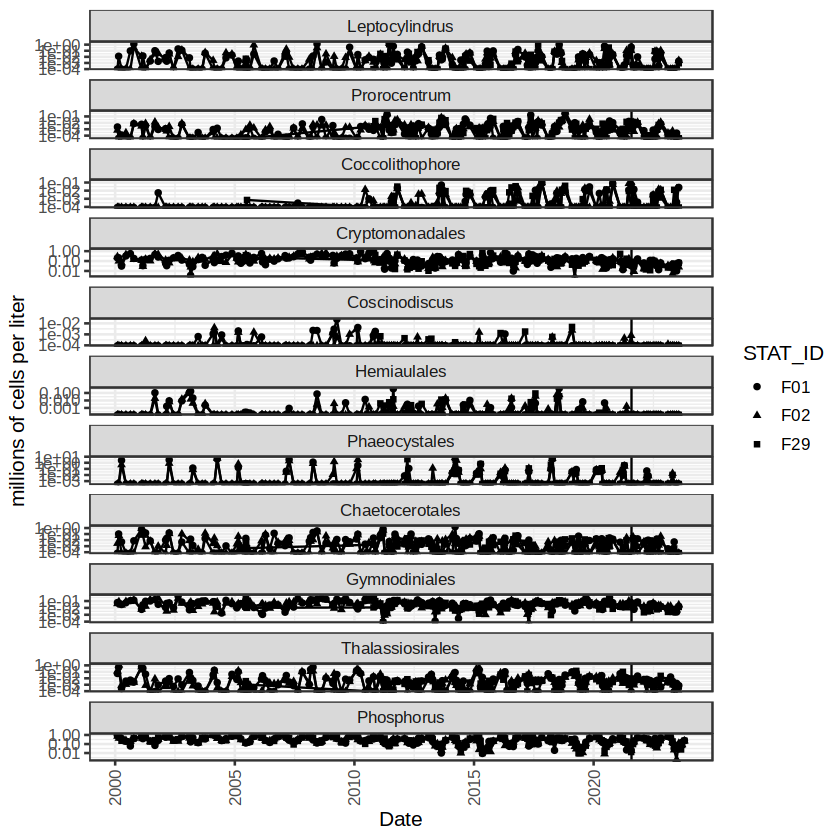

In [26]:
infill_dates_crypto = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES","CRYPTOPHYTES")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date","STAT_ID"),names_from="DESCR",values_from="Group_Ct")

infill_dates_crypto[is.na(infill_dates_crypto)]=0

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")|
                               starts_with("STAT_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)|grepl("Thalassios",DESCR)|grepl("Cryptomonas",DESCR)|
                  grepl("Chilomonas",DESCR)|grepl("Hemiselmis",DESCR)|grepl("Hemiaulus",DESCR)|
                  grepl("Eucampia",DESCR)|grepl("Cerataulina",DESCR)|
                  grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)|
                  grepl("Gymnodinium",DESCR)|grepl("Gyrodinium",DESCR)|
                  grepl("Karenia",DESCR)|
                  grepl("Phaeo",DESCR)|
                  grepl("Chaeto",DESCR)|
                  grepl("Coscino",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales",
                                 grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)~
                                 "Prymesiophyte",
                                 grepl("Hemiaulus",DESCR)|grepl("Eucampia",DESCR)|
                                 grepl("Cerataulina",DESCR)~
                                 "Hemiaulales",
                                 grepl("Coscino",DESCR)~
                                 "Coscinodiscus",
                                 grepl("Gymnodinium",DESCR)|grepl("Gyrodinium",DESCR)|
                                 grepl("Karenia",DESCR)~
                                 "Gymnodiniales",
                                 grepl("Chaetocero",DESCR)~"Chaetocerotales",
                                 grepl("Phaeo",DESCR)~
                                 "Phaeocystales")) %>%
    dplyr::group_by(type,Date,STAT_ID) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

infill_dates_tot = infill_dates_crypto  %>% 
    tidyr::pivot_longer(cols=!starts_with("Date")& !starts_with("STAT_ID"),
                        names_to = "organism", values_to="counts")  %>%
    dplyr::group_by(STAT_ID,Date) %>%
    dplyr::summarize(total_counts=sum(counts))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(infill_dates_tot) %>%
    dplyr::mutate(Scaled_Ct = Group_Ct) %>% # / total_counts) %>%
    dplyr::bind_rows(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("type"="Category","Scaled_Ct"="FFU_RESULT")))%>%
    #dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore",
                                            "Cryptomonadales",
                                            "Coscinodiscus",
                                            "Hemiaulales",
                                            "Phaeocystales",
                                            "Chaetocerotales",
                                            "Gymnodiniales",
                                            "Thalassiosirales",
                                            "Prymesiophyte",
                                            "Phosphorus")))) + 
    geom_point(aes(x=Date,y=Scaled_Ct,shape=STAT_ID)) +  
    geom_line(aes(x=Date,y=Scaled_Ct,group=STAT_ID)) + 
    scale_y_log10()+
    geom_vline(aes(xintercept=as.Date("2021-07-27",format="%Y-%m-%d"))) + 
    theme_bw(base_size=12) + facet_wrap(~type,scales="free_y",ncol=1) +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends
#ggsave("../figures/abundances_w_phosphate.pdf")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type, Date, and STAT_ID.
ℹ Output i

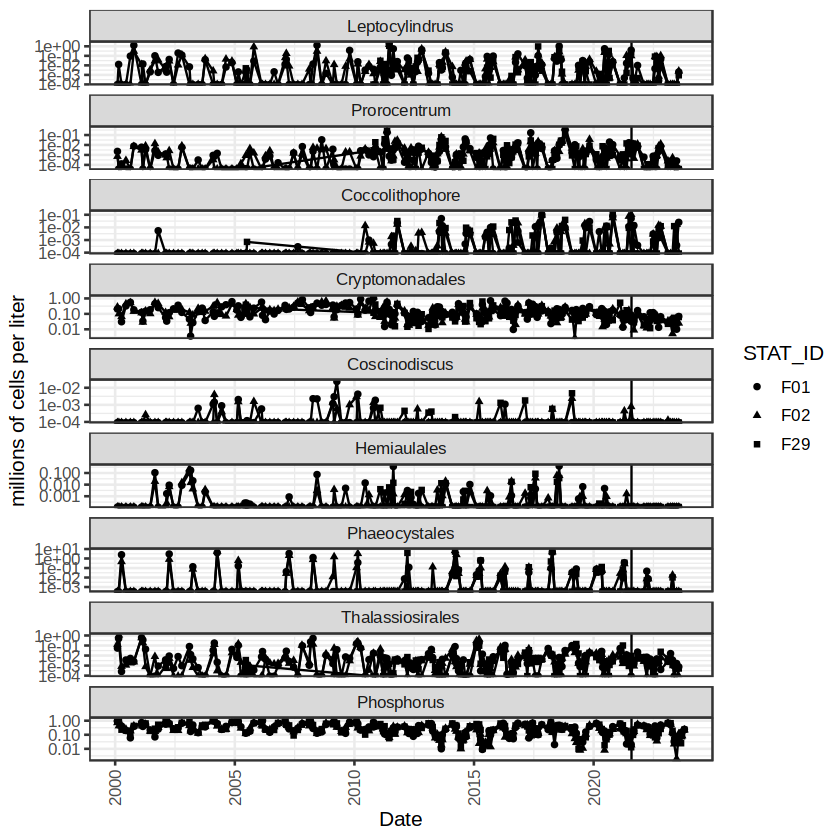

In [22]:
infill_dates_crypto = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES","CRYPTOPHYTES")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date","STAT_ID"),names_from="DESCR",values_from="Group_Ct")

infill_dates_crypto[is.na(infill_dates_crypto)]=0

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")|
                               starts_with("STAT_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)|grepl("Thalassios",DESCR)|grepl("Cryptomonas",DESCR)|
                  grepl("Chilomonas",DESCR)|grepl("Hemiselmis",DESCR)|grepl("Hemiaulus",DESCR)|
                  grepl("Eucampia",DESCR)|grepl("Cerataulina",DESCR)|
                  grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)|
                  grepl("Phaeo",DESCR)|
                  grepl("Coscino",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales",
                                 grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)~
                                 "Prymesiophyte",
                                 grepl("Hemiaulus",DESCR)|grepl("Eucampia",DESCR)|
                                 grepl("Cerataulina",DESCR)~
                                 "Hemiaulales",
                                 grepl("Coscino",DESCR)~
                                 "Coscinodiscus",
                                 grepl("Phaeo",DESCR)~
                                 "Phaeocystales")) %>%
    dplyr::group_by(type,Date,STAT_ID) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

infill_dates_tot = infill_dates_crypto  %>% 
    tidyr::pivot_longer(cols=!starts_with("Date")& !starts_with("STAT_ID"),
                        names_to = "organism", values_to="counts")  %>%
    dplyr::group_by(STAT_ID,Date) %>%
    dplyr::summarize(total_counts=sum(counts))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(infill_dates_tot) %>%
    dplyr::mutate(Scaled_Ct = Group_Ct) %>% # / total_counts) %>%
    dplyr::bind_rows(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("type"="Category","Scaled_Ct"="FFU_RESULT")))%>%
    #dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore",
                                            "Cryptomonadales",
                                            "Coscinodiscus",
                                            "Hemiaulales",
                                            "Phaeocystales",
                                            "Thalassiosirales",
                                            "Prymesiophyte",
                                            "Phosphorus")))) + 
    geom_point(aes(x=Date,y=Scaled_Ct,shape=STAT_ID)) +  
    geom_line(aes(x=Date,y=Scaled_Ct,group=STAT_ID)) + 
    geom_vline(aes(xintercept=as.Date("2021-07-27",format="%Y-%m-%d"))) + 
    scale_y_log10()+
    theme_bw(base_size=12) + facet_wrap(~type,scales="free_y",ncol=1) +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends
#ggsave("../figures/abundances_w_phosphate.pdf")

In [17]:
colnames(infill_dates_crypto)

[1] "Date"                                                                 
  [2] "STAT_ID"                                                              
  [3] "Centric diatom sp. group 1 diam <10 microns"                          
  [4] "Chaetoceros sp. group 1 diam <10 microns"                             
  [5] "Corethron criophilum"                                                 
  [6] "Guinardia delicatula"                                                 
  [7] "Rhizosolenia setigera"                                                
  [8] "Skeletonema costatum species complex"                                 
  [9] "Thalassiosira nordenskioeldii"                                        
 [10] "Thalassiosira sp. group 3 10-20 microns length"                       
 [11] "Cryptomonas sp. group 1 length <10 microns"                           
 [12] "Cryptomonas sp. group 2 length >10 microns"                           
 [13] "Gymnodinium sp. group 1 5-20 microns width, 10-20 microns length"     
 [14] "Gymnodinium sp. group 2 21-40 microns width, 21-50 microns length"    
 [15] "Gyrodinium spirale"                                                   
 [16] "Heterocapsa rotundata"                                                
 [17] "Prorocentrum micans"                                                  
 [18] "Protoperidinium bipes"                                                
 [19] "Cylindrotheca closterium"                                             
 [20] "Pennate diatom sp. group 2 10-30 microns length"                      
 [21] "Pennate diatom sp. group 3 31-60 microns length"                      
 [22] "Pleurosigma spp."                                                     
 [23] "Thalassionema nitzschioides"                                          
 [24] "Chaetoceros debilis"                                                  
 [25] "Chaetoceros sp. group 2 diam 10-30 microns"                           
 [26] "Leptocylindrus minimus"                                               
 [27] "Thalassiosira rotula"                                                 
 [28] "Chaetoceros didymus"                                                  
 [29] "Detonula confervacea"                                                 
 [30] "Thalassiosira anguste-lineata"                                        
 [31] "Thalassiosira sp. group 4 20-30 microns length"                       
 [32] "Gyrodinium sp. group 2 21-40 microns width, 21-50 microns length"     
 [33] "Prorocentrum minimum"                                                 
 [34] "Phaeocystis pouchetii"                                                
 [35] "Ceratium fusus"                                                       
 [36] "Ceratium lineatum"                                                    
 [37] "Ceratium longipes"                                                    
 [38] "Ceratium tripos"                                                      
 [39] "Dinophysis norvegica"                                                 
 [40] "Heterocapsa triquetra"                                                
 [41] "Bellerochea malleus"                                                  
 [42] "Dactyliosolen fragilissimus"                                          
 [43] "Leptocylindrus danicus"                                               
 [44] "Amphidinium spp."                                                     
 [45] "Scrippsiella trochoidea"                                              
 [46] "Guinardia flaccida"                                                   
 [47] "Ceratium macroceros"                                                  
 [48] "Pseudo-nitzschia pungens"                                             
 [49] "Chaetoceros contortus"                                                
 [50] "Chaetoceros decipiens"                                                
 [51] "Chaetoceros socialis"                                                 
 [52] "Ditylum brightwel

In [15]:
main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("phosphate"="FFU_RESULT")))%>%
    dplyr::filter((Date>as.Date("2020-12-01",format="%Y-%m-%d"))) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore"))) %>%
    dplyr::select(Date,phosphate,STAT_ID,type,Group_Ct) %>%
    dplyr::distinct() %>%
    tidyr::pivot_wider(id_cols = c("Date","phosphate","STAT_ID"),names_from="type",
                       values_from="Group_Ct") %>%
    dplyr::filter(STAT_ID=="F29"))+ 
    geom_point(aes(x=phosphate,y=Prorocentrum/max(Prorocentrum),
                   shape="Prorocentrales"),size=3,fill="black") +
    #geom_smooth(aes(x=phosphate,y=Coccolithophore/max(Coccolithophore)),
    #            method="lm")+
    geom_point(aes(x=phosphate,y=Coccolithophore/max(Coccolithophore),
                   shape="Coccolithophores"),size=3,fill="black") +  
    geom_point(aes(x=phosphate,y=Leptocylindrus/max(Leptocylindrus),
                   shape="Leptocylindrales"),size=3,fill="black") +    
    theme_bw(base_size=12) + #facet_wrap(~type,scales="free_y") +  
    #theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("fraction of maximum millions of cells per liter") + 
    xlab("Orthophosphate (uM)")+
    scale_shape_manual(values=c(25,23,21))
main_grp_trends

ggsave("../figures/orthophosphate_vs_counts.pdf")

Joining with `by = join_by(Date, STAT_ID)`
Warning message in dplyr::left_join(., processed_df %>% dplyr::filter(PARAM_CODE %in% :
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 57 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”
Warning message:
“Values from `Group_Ct` are not uniquely identified; output will contain
list-cols.
• Use `values_fn = list` to suppress this warning.
• Use `values_fn = {summary_fun}` to summarise duplicates.
• Use the following dplyr code to identify duplicates.
  {data} |>
  dplyr::summarise(n = dplyr::n(), .by = c(Date, phosphate, STAT_ID, type)) |>
  dplyr::filter(n > 1L)”
ERROR while rich displaying an object: Error in `geom_point()`:
! Problem while computing aesthetics.
ℹ Error occurred in the 1st layer.
Caused by error in `max()`:
! invalid 'type' (list) of argument

Traceback:
1.

ERROR: [1m[33mError[39m in `geom_point()`:[22m
[1m[22m[33m![39m Problem while computing aesthetics.
[36mℹ[39m Error occurred in the 1st layer.
[1mCaused by error in `max()`:[22m
[33m![39m invalid 'type' (list) of argument


In [ ]:
main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("phosphate"="FFU_RESULT")))%>%
    dplyr::filter((Date>as.Date("2020-12-01",format="%Y-%m-%d"))) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore"))) %>%
    dplyr::select(Date,phosphate,STAT_ID,type,Group_Ct) %>%
    dplyr::distinct() %>%
    tidyr::pivot_wider(id_cols = c("Date","phosphate","STAT_ID"),names_from="type",
                       values_from="Group_Ct") %>%
    dplyr::filter(STAT_ID=="F29"))+ 
    geom_hist(aes(x=phosphate,y=Prorocentrum/max(Prorocentrum),
                   shape="Prorocentrales"),size=3,fill="black") + 
    geom_point(aes(x=phosphate,y=Coccolithophore/max(Coccolithophore),
                   shape="Coccolithophores"),size=3,fill="black") +  
    geom_point(aes(x=phosphate,y=Leptocylindrus/max(Leptocylindrus),
                   shape="Leptocylindrales"),size=3,fill="black") +    
    theme_bw(base_size=12) + #facet_wrap(~type,scales="free_y") +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter") + 
    scale_shape_manual(values=c(25,23,21))
main_grp_trends

In [ ]:
## Spearman correlations of counts and metaT.

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)|grepl("Thalassios",DESCR)|grepl("Cryptomonas",DESCR)|
                  grepl("Chilomonas",DESCR)|grepl("Hemiselmis",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales")) %>%
    dplyr::group_by(type,Date) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

merged_for_test = for_plotting %>% 
    dplyr::left_join(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("phosphate"="FFU_RESULT")))%>%
    dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore",
                                            "Thalassiosirales",
                                            "Cryptomonadales"))) %>%
    dplyr::select(Date,phosphate,STAT_ID,type,Group_Ct) %>%
    dplyr::distinct() %>%
    tidyr::pivot_wider(id_cols = c("Date","phosphate","STAT_ID"),names_from="type",
                       values_from="Group_Ct") %>% dplyr::filter(STAT_ID=="F29")

In [52]:
cor(merged_for_test$Coccolithophore, merged_for_test$phosphate, method = "spearman")

[1] -0.6467636

In [ ]:
for_plotting %>% 
    dplyr::left_join(processed_df %>% 
                     dplyr::filter(Category%in%c("Phosphorus")) %>%
                     dplyr::rename(c("phosphate"="FFU_RESULT")))%>%
    dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore"))) 

`summarise()` has grouped output by 'Date', 'ORDERED_DEPTH_CODE', 'GROUP_ID',
'DESCR'. You can override using the `.groups` argument.
`summarise()` has grouped output by 'Date', 'ORDERED_DEPTH_CODE', 'GROUP_ID'.
You can override using the `.groups` argument.
`summarise()` has grouped output by 'regime', 'DESCR'. You can override using
the `.groups` argument.
`summarise()` has grouped output by 'regime', 'DESCR', 'GROUP_ID'. You can
override using the `.groups` argument.
Saving 7 x 7 in image


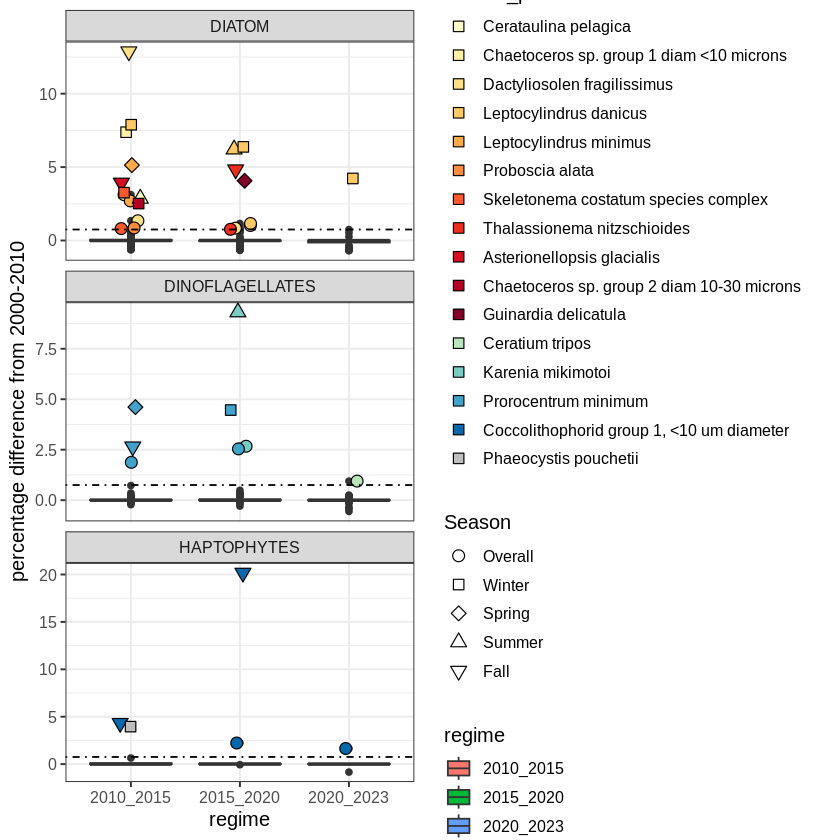

In [13]:
infill_dates = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES")) %>%
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date"),names_from="DESCR",values_from="Group_Ct")

infill_dates[is.na(infill_dates)]=0

group_connect = paired_data %>% dplyr::select(GROUP_ID,DESCR) %>%
    dplyr::mutate(DESCR=trimws(DESCR)) %>%
    dplyr::distinct() %>% dplyr::filter(!is.na(GROUP_ID) & !is.na(DESCR))

for_plotting = infill_dates %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::mutate(GROUP_ID = case_when(grepl("DIATOM",GROUP_ID)~"DIATOM",
                                      TRUE~GROUP_ID))%>%
    dplyr::mutate(Year = year(as.Date(Date,format='%d-%b-%Y %H:%M:%S')),
                 Month = month(as.Date(Date,format='%d-%b-%Y %H:%M:%S'))) %>%
    dplyr::mutate(regime = case_when(Year > 2020 ~ "2020_2023",
                                     Year > 2015 ~ "2015_2020",
                                     Year > 2010 ~ "2010_2015",
                                    TRUE ~"early")) %>%
    dplyr::group_by(regime,DESCR,GROUP_ID) %>% dplyr::summarize(meanCt = mean(Group_Ct)) %>%
    tidyr::pivot_wider(id_cols=c("DESCR","GROUP_ID"),names_from="regime",
                       values_from="meanCt")%>%
    tidyr::pivot_longer(cols=!(starts_with("GROUP_ID")|starts_with("DESCR")|starts_with("early")),
                       names_to="regime",
                       values_to="value") %>%
    dplyr::mutate(labeled_pts = case_when(((value)-(early))/(early+0.01)> 0.75~DESCR,
                                          TRUE~NA)) %>%
    dplyr::mutate(Season="Overall")

for_plotting_by_season = infill_dates %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::mutate(GROUP_ID = case_when(grepl("DIATOM",GROUP_ID)~"DIATOM",
                                      TRUE~GROUP_ID))%>%
    dplyr::mutate(Year = year(as.Date(Date,format='%d-%b-%Y %H:%M:%S')),
                 Month = month(as.Date(Date,format='%d-%b-%Y %H:%M:%S'))) %>%
    dplyr::mutate(regime = case_when(Year > 2020 ~ "2020_2023",
                                     Year > 2015 ~ "2015_2020",
                                     Year > 2010 ~ "2010_2015",
                                    TRUE ~"early")) %>%
    dplyr::mutate(Year = year(as.Date(Date,format='%d-%b-%Y %H:%M:%S')),
                  Month = month(as.Date(Date,format='%d-%b-%Y %H:%M:%S')),
                  Day = day(as.Date(Date,format='%d-%b-%Y %H:%M:%S')),
                  Date=as.Date(Date,format='%d-%b-%Y %H:%M:%S'),
                  Season = case_when((Month <= 3)&(Day<=21)~"Winter",
                                     (Month <=6) & (Day<=21)~"Spring",
                                     (Month <=9)&(Day<=21)~"Summer",
                                     (Month<=12)&(Day<=21)~"Fall",
                                     TRUE~"Winter")) %>%
    dplyr::group_by(regime,DESCR,GROUP_ID,Season) %>% 
    dplyr::summarize(meanCt = mean(Group_Ct)) %>%
    tidyr::pivot_wider(id_cols=c("DESCR","GROUP_ID","Season"),names_from="regime",
                       values_from="meanCt") %>%
    tidyr::pivot_longer(cols=!(starts_with("GROUP_ID")|starts_with("DESCR")|
                               starts_with("Season")|starts_with("early")),
                       names_to="regime",
                       values_to="value") %>%
    dplyr::mutate(labeled_pts = case_when(((value)-(early))/(early+0.01)> 2.5~DESCR,
                                          TRUE~NA))

redsPalette = colorRampPalette(brewer.pal(9, "YlOrRd"))

ggplot(for_plotting)+
    geom_boxplot(aes(x=regime,y=((value)-(early))/(early+0.01),group=paste0(GROUP_ID,regime),
                     fill=regime))+new_scale_fill() + 
    geom_jitter(data=for_plotting %>% dplyr::bind_rows(for_plotting_by_season) %>% 
               dplyr::filter(!is.na(labeled_pts))%>% 
               dplyr::mutate(labeled_pts=factor(labeled_pts,levels=(for_plotting %>% 
                                                dplyr::bind_rows(for_plotting_by_season) %>%
                                                dplyr::distinct(labeled_pts,.keep_all=TRUE) %>%
                                                dplyr::filter(!is.na(labeled_pts)) %>%
               dplyr::arrange(GROUP_ID))$labeled_pts)),
               aes(x=regime,y=((value)-(early))/(early+0.01),group=paste0(regime,GROUP_ID),
                   fill=labeled_pts,shape=Season), na.rm=TRUE,
               width=0.1,height=0,size=3)+
    guides(fill = guide_legend(override.aes = list(alpha = 1, shape = 22)))+
    scale_shape_manual(values=c(21,22,23,24,25),breaks=c("Overall","Winter","Spring","Summer","Fall")) +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    facet_wrap(~GROUP_ID,nrow=3,scales="free_y") + 
    geom_hline(aes(yintercept=0.75),linetype="dotdash") + theme_bw(base_size=12) + 
    ylab("percentage difference from 2000-2010")+ 
    scale_fill_manual(values=c(redsPalette(11),
                               brewer.pal(5,"GnBu")[2:5],"gray","white"))

ggsave("../figures/supplemental_seasonal_plot.pdf")